# PHYS20762 - Project 2

Callum Williamson

University of Manchester

Initialise our python interpreter:

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math

plt.rcParams["text.usetex"] = True # In order to use latex on plots.

In this project I intend to numerically investigate a spring-mass system which is subjected to an external force $F(t)$. 

$m\ddot{x} + b\dot{x} + kx = ma(t) + bv(t) + kx(t) = F(t)$.

Where:
$x(t)$ is the position, $\dot{x} = v(t)$ is the velocity and $\ddot{x} = a(t)$ is the acceleration.

$k$ is the spring constant, $m$ is the mass and $b$ is the damping constant.

Physical parameters given to me.

In [2]:
k = 0.89 # spring constant kg/s^2.
 
m = 2.92 # mass kg.

In [3]:
omega_0 = np.sqrt(k / m) # Natural frequency.

The damping constant $b$ is not given. Below are the ones used throughout the code.

i) $\frac{b_{crit}}{2} = b_i$

ii) $b_{crit}$

iii) $2b_{crit} = b_{iii}$

In [4]:
b_1 = 0.08 # kg/s. Using this value for now.

b_2 = 3.2242

b_crit = np.sqrt(4 * k * m)

# Chosen i & iii as they are letters used to denote the use of these damping constants in section 2.

b_i = b_crit / 2

b_iii = 2 * b_crit

## 1. Investigation of zero external force $F(t) = 0$

$m\ddot{x} + b\dot{x} + kx = 0$

The aim of this section is to calculate solutions of  $x(t)$ for the four proposed numerical methods: Euler, improved Euler, Verlet & Euler-Cromer.

When the external force is equal to zero it is easy to find a solution analytically. This can allow us to check the validity of our numerical methods.

The reliability of these methods is useful to know for when $F(t) \neq 0$, as it is much harder to find a solution analytically. We use our previous 'factcheck' to understand to what degree we can trust these numerical methods.

NOTE: In this section I have removed the process of checking the methods and plotting them. Instead cleaning up this section and making it more straight to the point. It includes the definitions of the analytical solutions and the numerical methods with a short comparison at the end. I did this as I feel the checking did not add much to the notebook, was very long and therefore took away from the importance of the findings in the later sections which was more the point of this project. However if you wish to see this I have put this raw section in an appendix at the end.

### 1.1 Analytical solutions - zero external force

Finding the analytical solutions.

$m\ddot{x} + b\dot{x} + kx = 0$

$\ddot{x} + \frac{b}{m}\dot{x} + \frac{k}{m}x = 0$

$\ddot{x} + \gamma\dot{x} + \omega_0^2x = 0$, where $\gamma = \frac{b}{m}$ and $\omega_0^2 = \frac{k}{m}$.

Starting with the general solution to light damping, $x(t) = A \exp\left(-\frac{\gamma}{2} t\right) \cos(\omega t + \Phi); \quad \omega = \sqrt{\omega_0^2 - \frac{\gamma^2}{4}}.$
Where $A$ is an amplitude constant and $\Phi$ is a phase.

$x(t) = A \exp\left(-\frac{\gamma}{2} t\right) \cos(\omega t + \Phi)$

$v(t) = \frac{d}{dt}x(t)$, therefore $v(t) = - A \exp\left(-\frac{\gamma}{2} t\right) \left( \frac{\gamma}{2} \cos(\omega t + \Phi) + \omega \sin(\omega t + \Phi) \right)$

We can find that the initial conditions provided relate to $A$ & $\Phi$ as follows:

$x_0 = Acos(\Phi)$

$v_0 = -A \left( \frac{\gamma}{2} \cos(\Phi) + \omega \sin(\Phi) \right)$

From above we can find $A$ & $\Phi$ in terms of the initial conditions $x_0$ & $v_0$.

$A = \sqrt{x_0^2 + \frac{(\frac{x_0 \gamma}{2} + v_0)^2}{\omega^2}}$

$\Phi = \arctan(- \frac{v_0 + \frac{x_0 \gamma}{2}}{x_0 \omega})$



We also must consider heavy & critical damping. Where $b_{cr}$ is the critical damping constant.

If $\frac{\gamma^2}{4} < \omega_0^2$, $b < b_{cr}$, this is light damping.

If $\frac{\gamma^2}{4} > \omega_0^2$, $b > b_{cr}$, this is heavy damping.

If $\frac{\gamma^2}{4} = \omega_0^2$, $b = b_{cr}$ this is critical damping.

The solution for heavy damping is $x(t) = \exp\left( -\frac{\gamma}{2} t \right) \left[ C \exp(\alpha t) + D \exp(-\alpha t) \right]$, where $\alpha = \sqrt{\frac{\gamma^2}{4} - \omega_0^2}$.

$v(t) = e^{-\frac{\gamma}{2} t} \left[ C (\alpha - \frac{\gamma}{2}) e^{\alpha t} - D (\alpha + \frac{\gamma}{2}) e^{-\alpha t} \right]$

$C$ & $D$ are related to the initial conditions by the following:

$C = \frac{x_0 \left(\alpha + \frac{\gamma}{2} \right) + v_0}{2\alpha}$

$D = \frac{x_0 \left(\alpha - \frac{\gamma}{2} \right) - v_0}{2\alpha}$

The solution to critical damping is:

$x(t) = E \exp\left(-\frac{\gamma}{2} t\right) + F t \exp\left(-\frac{\gamma}{2} t\right)$

$v(t) = \exp(-\frac{\gamma}{2} t)(-\frac{\gamma}{2} E + F -\frac{\gamma}{2}Ft )  $

Where $E$ & $F$ are related to the initial conditions by:

$E = x_0$

$F = \frac{\gamma}{2}x_0 + v_0$ 

Now defining the analytical solution function.

In [5]:
def analytical_solutions(h, T, x_0, v_0, b=b_1):
    """
    h is the step size in seconds.
    T is the time we are integrating until, in seconds.
    x_0 is the initial condition for position.
    v_0 is the initial condition for velocity.
    b is the damping constant. It is b_1 unless stated otherwise.

    This function uses the equations in the above markdown to find the analytical solutions.
    Using if statements to decide what kind of damping it is.

    It returns the arrays of position, velocity & time.
    """
    
    no_steps = int(T/h) # Determine how many whole number steps are within T. Each step is one i.
    t = np.arange(0, (no_steps * h), h) # Define time intervals for each step. Useful for when we plot.

    gamma = b / m
    omega_0_sqrd = k / m 
    # omega = np.sqrt( omega_0_sqrd - (gamma**2 / 4)) Is imaginary for heavy and critical. Just moved it inside the if for light damping.

    if b < b_crit:

        #print("light")

        omega = np.sqrt( omega_0_sqrd - (gamma**2 / 4))
        
        A = np.sqrt(x_0**2 + ( (x_0 * gamma /2) + v_0 )**2 / omega**2)

        Phi = np.arctan2(-1 * ( v_0 + (x_0 * gamma /2) ), (x_0 * omega)) # arctan2 handles when the argument is around 0 better.

        x = A * np.exp(- t * gamma / 2) * np.cos(omega * t + Phi) # Calculating the analytical x solutions.

        v = - A * np.exp(- t * gamma / 2) * ( (gamma / 2) * np.cos(omega * t + Phi) + omega * np.sin(omega * t + Phi) ) # Calculating the analytical v solutions. 
    
    elif round(b, 4) == round(b_crit, 4): # The round is used otherwise b must match the critical b to a very high precision
    
        #print("critical")
    
        E = x_0
    
        F = (gamma / 2) * x_0 + v_0
    
        x = E * np.exp(- gamma * t / 2) + F * t * np.exp(- gamma * t / 2)
    
        v = np.exp(- gamma * t / 2) * ((- gamma / 2 ) * E + F + (- gamma / 2) * F * t)
    
    elif b > b_crit:

        #print("heavy")

        alpha = np.sqrt((gamma**2 / 4) - omega_0_sqrd)

        C = (x_0 * (alpha + gamma / 2) + v_0) / (2 * alpha)

        D = (x_0 * (alpha - gamma / 2) - v_0) / (2 * alpha)

        x = np.exp(- gamma * t / 2) * (C * np.exp(alpha * t) + D * np.exp(- alpha * t))

        v = np.exp(- gamma * t / 2) * (C * (alpha - gamma / 2) * np.exp(alpha * t) - D * (alpha + gamma / 2) * np.exp(- alpha * t))

        
    return x, v, t

### 1.2 Euler's method - zero external force

Eulers method approximates the integral $y$ as a sum of $\delta y = \frac{dy}{dx}\delta t = y = \frac{dy}{dx} h $, where $\delta t = h $ is the step size.

We can see:

$x(t+h) = x(t) + hv(t)$

$v(t+h) = v(t) + ha(t)$

$x_{i+1} = x_i + hv_i$ (1.3)

$v_{i+1} = v_i + ha_i$ (1.4)

where $a_i = -\frac{k}{m}x_i - \frac{b}{m}v_i$ (1.5)

This is Eulers method.

In [6]:
def eulers_method(h, T, x_0, v_0, b=b_1):
    """
    h is the step size in seconds.
    T is the time we are integrating until, in seconds.
    x_0 is the initial condition for position.
    v_0 is the initial condition for velocity.
    b is the damping constant. It is b_1 unless stated otherwise.

    This function uses the equations in the above markdown to carry out euler's numerical method.

    It returns the arrays of position, velocity & time.
    """

    no_steps = int(T/h) # Determine how many whole number steps are within T. Each step is one i.
    
    x = np.zeros(no_steps) # Empty array for position.
    v = np.zeros(no_steps) # Empty array for velocity.

    # Use the initial conditions from the function arguments.
    x[0] = x_0
    v[0] = v_0

    for i in range(no_steps - 1):

        a = -(k / m) * x[i] - (b / m) * v[i] # Acceleration at step i, using eqn 1.5.

        x[i+1] = x[i] + h * v[i] # x at later step i+1, using eqn 1.3.
        v[i+1] = v[i] + h * a # v at later step i+1, using eqn 1.4.

    t = np.arange(0, (no_steps * h), h) # Define time intervals for each step. Useful for when we plot.
    
    return x, v, t

### 1.3 Improved Euler's method - zero external force

We can improve upon Euler's method by using an extra term in the taylor series expansion for $x$.

$x(t + h) = x(t) + h\dot{x}(t) + \frac{1}{2}h^2\ddot{x}(t) + O(h^3)$, where the local error is now of a higher order than the standard euler method.

$x_{i+1} = x_i + hv_i + \frac{h^2}{2}a_i$

Velocity step stays the same, $v_{i+1} = v_i + ha_i$, so does the order of local error which will restrict the overall global error.

As before, $a_i = -\frac{k}{m}x_i - \frac{b}{m}v_i$

In [7]:
def eulers_improved_method(h, T, x_0, v_0, b=b_1):
    """
    h is the step size in seconds.
    T is the time we are integrating until, in seconds.
    x_0 is the initial condition for position.
    v_0 is the initial condition for velocity.
    b is the damping constant. It is b_1 unless stated otherwise.

    This function uses the equations in the above markdown to carry out euler's improved numerical method.

    It returns the arrays of position, velocity & time.
    """

    no_steps = int(T/h) # Determine how many whole number steps are within T. Each step is one i.
    
    x = np.zeros(no_steps) # Empty array for position.
    v = np.zeros(no_steps) # Empty array for velocity.

    # Use the initial conditions from the function arguments.
    x[0] = x_0
    v[0] = v_0

    for i in range(no_steps - 1):

        a = -(k / m) * x[i] - (b / m) * v[i] # Acceleration at step i, using eqn 1.5.

        x[i+1] = x[i] + h * v[i] + (h**2 / 2) * a # x at later step i+1, using eqn 1.6.
        v[i+1] = v[i] + h * a # v at later step i+1, using eqn 1.4.

    t = np.arange(0, (no_steps * h), h) # Define time intervals for each step. Useful for when we plot.
    
    return x, v, t

### 1.4 Verlet's Method - zero external force

Verlet's Method starts by looking at a centred derivitive. The derivation is quite long so I am only showing the final results.

$x'(t) = \lim_{h \to 0} \frac{x(t+h) - x(t-h)}{2h}$

From which we can determine:

$v_i = \frac{x_{i+1} - x_{i-1}}{2h} + O(h^2)$

$a_i = \frac{x_{i+1} + x_{i-1} - 2x_i}{h^2} + O(h^2)$

Rearranging to find:

$x_{i+1} = 2x_i - x_{i-1} + h^2 a_i + O(h^4)$ Note the local error is of a fourth order, more accurate.

$a_i = -\frac{k}{m} x_i - \frac{b}{m} v_i$

$v_i = \frac{x_{i+1} - x_{i-1}}{2h}$

Rearranging so that it is only in terms of $x$.

$x_{i+1} = A x_i + B x_{i-1}$,

where $A = 2 \frac{(2m - k h^2)}{D}, \quad B = \frac{(b h - 2m)}{D}, \quad D = 2m + b h$

Here we can see Verlet's method is not self starting. We must know the previous term $i-1$. Therefore an alternative method must be used to initialise the method.

In [8]:
def verlets_method(h, T, x_0, v_0, b=b_1):
    """
    h is the step size in seconds.
    T is the time we are integrating until, in seconds.
    x_0 is the initial condition for position.
    v_0 is the initial condition for velocity.
    b is the damping constant. It is b_1 unless stated otherwise.

    This function uses the equations in the above markdown to carry out Verlet's numerical method.

    For the first step it must use another method as discussed in the above markdown. Improved euler's is used here for more accuracy.

    It returns the arrays of position, velocity & time.
    """
    
    no_steps = int(T/h) # Determine how many whole number steps are within T. Each step is one i.

    t = np.arange(0, (no_steps * h), h) # Define time intervals for each step. Useful for when we plot.
    
    x = np.zeros(no_steps) # Empty array for position.
    v = np.zeros(no_steps) # Empty array for velocity.

    # Use the initial conditions from the function arguments.
    x[0] = x_0
    v[0] = v_0
    
    D = 2 * m + b * h

    A =  2 * (2 * m - k * h**2) / D

    B = (b * h - 2 * m) / D

    # Use improved euler's method to find (i) from (i - 1)

    # Using x_0 / x[0] as (i - 1) and x_1 / x[1] as (i) for example.

    a_0 = -(k / m) * x[0] - (b / m) * v[0] # Acceleration at step (i - 1)

    x[1] = x_1 = x[0] + h * v[0] + h**2 * a_0 / 2 # Improved Euler's method used for initialisation step.
    v[1] = v_1 = v[0] + h * a_0

    

    for i in range(1, no_steps - 1): # The first argument in range starts the for loop at index 1 (i). If we started from index 0 we would not be able to access (i - 1).

        x[i+1] = (A * x[i]) + (B * x[i-1])

        v[i] = (x[i+1] - x[i-1]) / (2 * h) # Incase we are interested in velocity. Although we'll have one less term.

    return x, v, t

Below I define a Verlet's method with Standard Euler's as the initialisation step. This won't be used until section 4.1. 

In [9]:
def verlets_method_standard(h, T, x_0, v_0, b=b_1):
    """
    h is the step size in seconds.
    T is the time we are integrating until, in seconds.
    x_0 is the initial condition for position.
    v_0 is the initial condition for velocity.
    b is the damping constant. It is b_1 unless stated otherwise.

    This function uses the equations in the above markdown to carry out Verlet's numerical method.

    For the first step it must use another method as discussed in the above markdown. Standard euler's is used here for the initialisation step.

    It returns the arrays of position, velocity & time.
    """
    
    no_steps = int(T/h) # Determine how many whole number steps are within T. Each step is one i.

    t = np.arange(0, (no_steps * h), h) # Define time intervals for each step. Useful for when we plot.
    
    x = np.zeros(no_steps) # Empty array for position.
    v = np.zeros(no_steps) # Empty array for velocity.

    # Use the initial conditions from the function arguments.
    x[0] = x_0
    v[0] = v_0
    
    D = 2 * m + b * h

    A =  2 * (2 * m - k * h**2) / D

    B = (b * h - 2 * m) / D

    # Use euler's method to find (i) from (i - 1)

    # Using x_0 / x[0] as (i - 1) and x_1 / x[1] as (i) for example.

    a_0 = -(k / m) * x[0] - (b / m) * v[0] # Acceleration at step (i - 1)

    x[1] = x_1 = x[0] + h * v[0] # + h**2 * a_0 / 2 (Removing the improved euler part)
    v[1] = v_1 = v[0] + h * a_0

    

    for i in range(1, no_steps - 1): # The first argument in range starts the for loop at index 1 (i). If we started from index 0 we would not be able to access (i - 1).

        x[i+1] = (A * x[i]) + (B * x[i-1])

        v[i] = (x[i+1] - x[i-1]) / (2 * h) # Incase we are interested in velocity. Although we'll have one less term.

    return x, v, t

As discussed in the appendix 6.4 the velcoity arrays final term is zero, therefore use [:-1] throughout.

### 1.5 Euler-Cromer Method - zero external force

The Euler-Cromer method is an adjustment on the Euler's method.

Original Euler's method:

$x_{i+1} = x_i + hv_i$

$v_{i+1} = v_i + ha_i$

where $a_i = -\frac{k}{m}x_i - \frac{b}{m}v_i$

Euler-Cromer adjustment:

$x_{i+1} = x_i +hv_{i+1}$

$v_{i+1} = v_i + ha_i$

The Euler-Cromer is a Symplectic Integrator, energy preserving.

In [10]:
def euler_cromer_method(h, T, x_0, v_0, b=b_1):
    """
    h is the step size in seconds.
    T is the time we are integrating until, in seconds.
    x_0 is the initial condition for position.
    v_0 is the initial condition for velocity.
    b is the damping constant. It is b_1 unless stated otherwise.

    This function uses the equations in the above markdown to carry out the Euler-Cromer numerical method.

    It returns the arrays of position, velocity & time.
    """

    no_steps = int(T/h) # Determine how many whole number steps are within T. Each step is one i.
    
    x = np.zeros(no_steps) # Empty array for position.
    v = np.zeros(no_steps) # Empty array for velocity.

    # Use the initial conditions from the function arguments.
    x[0] = x_0
    v[0] = v_0

    for i in range(no_steps - 1):

        a = -(k / m) * x[i] - (b / m) * v[i]
        v[i+1] = v[i] + h * a # v at later step i+1
        x[i+1] = x[i] + h * v[i+1] # x at later step i+1
        

    t = np.arange(0, (no_steps * h), h) # Define time intervals for each step. Useful for when we plot.
    # Returning them each time may not be that useful as they should all be the same but I will keep it for when we adjust h & T.
    
    return x, v, t

### 1.6 Method comparison - zero external force

Let us compare the methods. For damping $b = b_i$, time step $h = 0.1$ and initial conditions $x_0 = 2$ & $v_0 = 0$m/s.

In [11]:
# Extracting the data to plot and compare. All times returned will be the same so just using t_comp.
# comp stands for comparison here.
x_an_comp, v_an_comp, t_comp = analytical_solutions(0.1, 50, 2, 0, b_i)
x_eul_comp, v_eul_comp, _ = eulers_method(0.1, 50, 2, 0, b_i)
x_imp_comp, v_imp_comp, _ = eulers_improved_method(0.1, 50, 2, 0, b_i)
x_ver_comp, v_ver_comp, _ = verlets_method(0.1, 50, 2, 0, b_i)
x_crom_comp, v_crom_comp, _ = euler_cromer_method(0.1, 50, 2, 0, b_i)

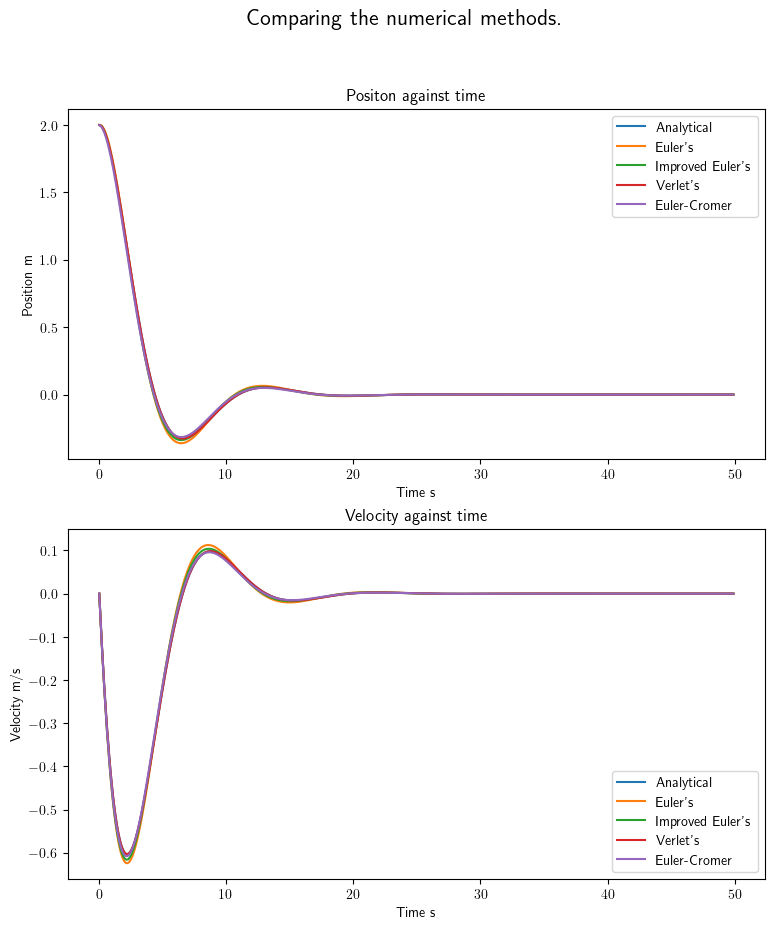

In [12]:
# Plot of the methods and compare
plt.rcParams["figure.figsize"] = (9,10)
fig, (ax1, ax2) = plt.subplots(2, 1)
fig.suptitle(r"Comparing the numerical methods.", fontsize=16)

# Position plot.
ax1.plot(t_comp, x_an_comp, label="Analytical")
ax1.plot(t_comp, x_eul_comp, label="Euler's")
ax1.plot(t_comp, x_imp_comp, label="Improved Euler's")
ax1.plot(t_comp, x_ver_comp, label="Verlet's")
ax1.plot(t_comp, x_crom_comp, label="Euler-Cromer")

ax1.set(xlabel=r"Time s")
ax1.set(ylabel="Position m")
ax1.set_title(r"Positon against time", fontsize=12)
ax1.legend()

# Velocity plot.
ax2.plot(t_comp, v_an_comp, label="Analytical")
ax2.plot(t_comp, v_eul_comp, label="Euler's")
ax2.plot(t_comp, v_imp_comp, label="Improved Euler's")
ax2.plot(t_comp, v_ver_comp, label="Verlet's")
ax2.plot(t_comp, v_crom_comp, label="Euler-Cromer")
ax2.set(xlabel=r"Time s")
ax2.set(ylabel="Velocity m/s")
ax2.set_title("Velocity against time", fontsize=12)
ax2.legend()

plt.show()

From this we can see with these conditions Euler's and improved Euler's are not the same as the analytical solutions. Verlet's and Euler-Cromer are graphically very close. It is reassuring that they all behave as we'd expect physically in the higher end of the light damping regime.

Let us investigate how the time step $h$ effects this error.

## 2. Investigation of time step $h$ and error 

In section 2 we will investigate how the choice of the step size $h$ affects the accuracy of the different methods. Determining the most accurate method and then using this method to show the effect of an external force $F(t)$.

We must choose a technique to determine the accuracy of the methods and show how $h$ affects this. Techniques chosen: 

-Energy Conservation.

-Error of Position & Velocity.

We will investigate damping coefficients $b$:

i) $\frac{b_{crit}}{2} = b_i$

ii) $b_{crit}$

iii) $2b_{crit} = b_{iii}$

### 2.1 Energy conservation

Firstly we will see if any of the methods do not conserve energy in the case of no damping $b = 0$. This doesn't show how $h$ effects the error however it is a good method to immediately see if any of the methods are invalid in certain scenarios.

In [13]:
# Extract the data for the analytical solution and all the methods for zero damping.
x_an_nodamp, v_an_nodamp, t_an_nodamp = analytical_solutions(0.01, 221, 2, 0, 0)

x_eul_nodamp, v_eul_nodamp, t_eul_nodamp = eulers_method(0.01, 221, 2, 0, 0)

x_imp_nodamp, v_imp_nodamp, t_imp_nodamp = eulers_improved_method(0.01, 221, 2, 0, 0)

x_ver_nodamp, v_ver_nodamp, t_ver_nodamp = verlets_method(0.01, 221, 2, 0, 0)

x_crom_nodamp, v_crom_nodamp, t_crom_nodamp = euler_cromer_method(0.01, 221, 2, 0, 0)

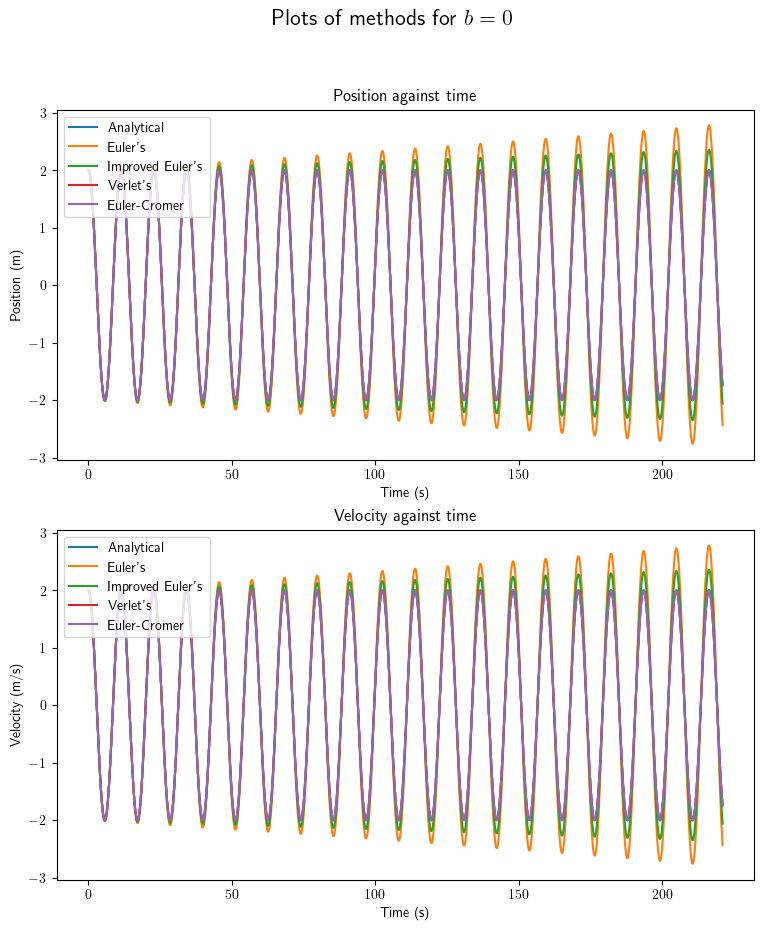

In [14]:
# Plot of the solutions to the no damping case.
plt.rcParams["figure.figsize"] = (9,10)
fig, (ax1, ax2) = plt.subplots(2, 1)
fig.suptitle(r"Plots of methods for $b = 0$", fontsize=16)

# Position plot.
ax1.plot(t_an_nodamp, x_an_nodamp, label="Analytical")
ax1.plot(t_eul_nodamp, x_eul_nodamp, label="Euler's")
ax1.plot(t_imp_nodamp, x_imp_nodamp, label="Improved Euler's")
ax1.plot(t_ver_nodamp, x_ver_nodamp, label="Verlet's")
ax1.plot(t_crom_nodamp, x_crom_nodamp, label="Euler-Cromer")
ax1.set(xlabel="Time (s)")
ax1.set(ylabel="Position (m)")
ax1.set_title("Position against time", fontsize=12)
ax1.legend(loc="upper left")
    
# Velocity plot.
ax2.plot(t_an_nodamp, x_an_nodamp, label="Analytical")
ax2.plot(t_eul_nodamp, x_eul_nodamp, label="Euler's")
ax2.plot(t_imp_nodamp, x_imp_nodamp, label="Improved Euler's")
ax2.plot(t_ver_nodamp, x_ver_nodamp, label="Verlet's")
ax2.plot(t_crom_nodamp, x_crom_nodamp, label="Euler-Cromer")
ax2.set(xlabel="Time (s)")
ax2.set(ylabel="Velocity (m/s)")
ax2.set_title("Velocity against time", fontsize=12)
ax2.legend(loc="upper left")

From this plot we can clearly see that both the standard and improved Euler methods gain amplitude. This makes no physical sense, damping being zero doesn't mean that the system gains energy. In this case Euler's & Improved Eulers do not conserve energy.

The plot above looks as if Verlets's and Euler-Cromer match the analytical solution, maintaining their energy throughout. However let us make sure.

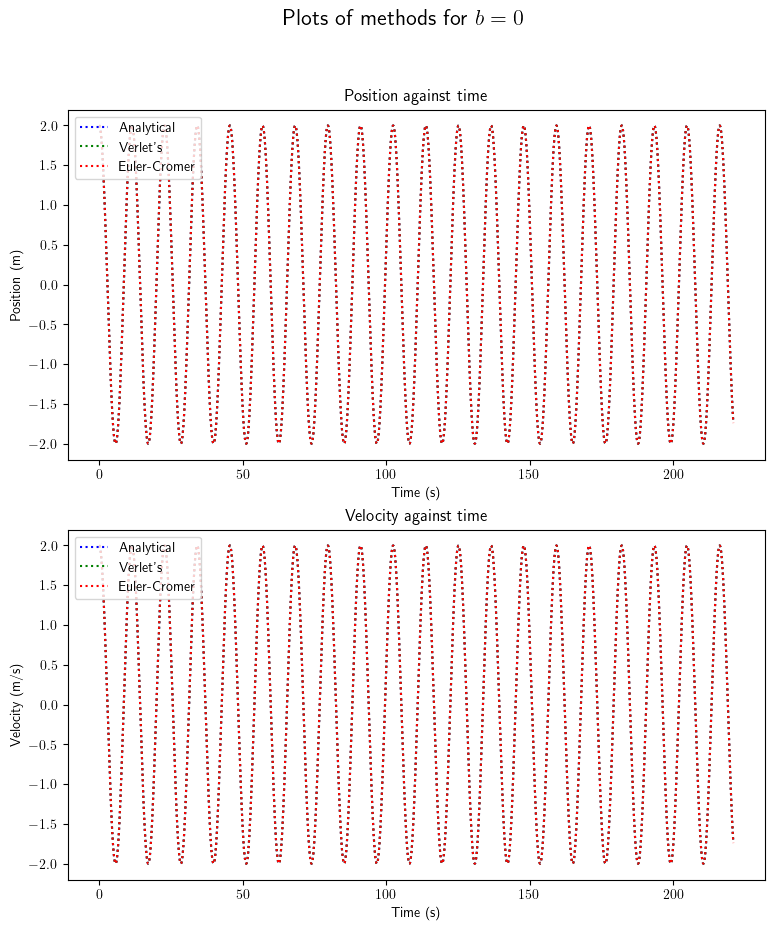

In [15]:
# Plot of the solutions to the no damping case.
plt.rcParams["figure.figsize"] = (9,10)
fig, (ax1, ax2) = plt.subplots(2, 1)
fig.suptitle(r"Plots of methods for $b = 0$", fontsize=16)

# Position plot.
ax1.plot(t_an_nodamp, x_an_nodamp, "b:", label="Analytical")
#ax1.plot(t_eul_nodamp, x_eul_nodamp, label="Euler's")
#ax1.plot(t_imp_nodamp, x_imp_nodamp, label="Improved Euler's")
ax1.plot(t_ver_nodamp, x_ver_nodamp, "g:", label="Verlet's")
ax1.plot(t_crom_nodamp, x_crom_nodamp, "r:", label="Euler-Cromer")
ax1.set(xlabel="Time (s)")
ax1.set(ylabel="Position (m)")
ax1.set_title("Position against time", fontsize=12)
ax1.legend(loc="upper left")
    
# Velocity plot.
ax2.plot(t_an_nodamp, x_an_nodamp, "b:", label="Analytical")
#ax2.plot(t_eul_nodamp, x_eul_nodamp, label="Euler's")
#ax2.plot(t_imp_nodamp, x_imp_nodamp, label="Improved Euler's")
ax2.plot(t_ver_nodamp, x_ver_nodamp,"g:", label="Verlet's")
ax2.plot(t_crom_nodamp, x_crom_nodamp, "r:", label="Euler-Cromer")
ax2.set(xlabel="Time (s)")
ax2.set(ylabel="Velocity (m/s)")
ax2.set_title("Velocity against time", fontsize=12)
ax2.legend(loc="upper left")

From this we can see the Verlet's and Euler-Cromer methods match the analytical solutions. Therefore preserving their energy.

From this investigation we can already see that the Euler's and Improved Euler's methods have issues where the Verlet's & the Euler-Cromer do not.

This is due to both Euler's and Improved Euler's being non-sympletic integrators, which means they are numerical methods which do not conserve energy.
Below I will show how this is encoded within Euler's method (this can be shown similarly for improved Euler's).

Euler's method for $b=0$:

$a_i = -\frac{k}{m} x_i$

$x_{i+1} = x_i + h v_i$

$v_{i+1} = v_i + h a_i = v_i - \frac{h k}{m} x_i$

Using these values in the equation for energy:

$E_{i+1} = \frac{1}{2} k x_{i+1}^2 + \frac{1}{2} m v_{i+1}^2 = \frac{1}{2} k x_i^2 + \frac{1}{2} m v_i^2 + \frac{1}{2} \frac{h^2 k^2 x_i^2}{m} + \frac{1}{2} h^2 k v_i^2 = E_i \left( 1 + \frac{k}{m} h^2 \right)$

Here we can see that every step causes an increase in energy, which is why we see Euler's method not conserving energy and in fact gaining.

Verlet's and the Euler-Cromer method are symplectic integrators and therefore can be seen as more reliable than the other two.

However let us move onto the next section to see how the accuracies compare and how time step effects them.

### 2.2 Position & Velocity error (Pos & Vel)

Determining the error for the position and velocity of the numerical methods is discussed below.

The absolute error, the absolute difference between the numerical method value at time $t_0$ and the analytical value at time $t_0$, was suggested.

$\sigma = |x_{num} - x_{an}|$ at a given time $t_0$.

Compare for different $h$ and the different methods.

However after consideration this seemed quite volatile. Changing the time $t_0$ at which this difference was taken can largely change our results ($t_0$ was always chosen to be within the oscillation).

I therefore thought the Mean Absolute Error was more appropiate.

$\sigma_{MAE} = \frac{1}{N} \sum_{i=1}^{N}|x_{num}(t_i) - x_{an}(t_i)|$

In [16]:
def err(T, x_0, v_0, b):
    """
    T is the time we are integrating until, in seconds.
    x_0 is the initial condition for position.
    v_0 is the initial condition for velocity.
    b is the damping constant. Typically either b_i, b_crit, or b_iii

    h is the step size in seconds. It is varied, taking the values from h_values.

    This function finds the error between the numerical method and the analytical solution using the mean absolute error.
    It find this for all the methods and for all the h values specified.
    Returning them in a 4 x no. h_value array, for position & velocity.

    Note runtime can be quite long due to the many h values and some of them being quite small.
    Also note the extra term in verlets velocity (zero) is not dealt with as it has a tiny effect.
    So not worth making the function more complicated. 
    """
    
    h_values = np.array([0.0001, 0.0005, 0.001, 0.005, 0.01, 0.03, 0.05, 0.075, 0.1])

    # Creating arrays/matrix to put the errors in. The rows represent a different h value , the columns a different method.
    # The columns a different method, each column representing: Euler's, Improved Euler's, Verlet' and Euler-Cromer.
    pos_sigmas_h = np.zeros((len(h_values), 4))
    vel_sigmas_h = np.zeros((len(h_values), 4))

    # Iterating through the different h values
    for i, h in enumerate(h_values):

        # Defing all the solutions for a certain h value. Function may have a long runtime due to the small h values.
        x_an, v_an, t = analytical_solutions(h, T, x_0, v_0, b)

        x_eul, v_eul, _ = eulers_method(h, T, x_0, v_0, b)

        x_imp, v_imp, _ = eulers_improved_method(h, T, x_0, v_0, b)

        x_ver, v_ver, _ = verlets_method(h, T, x_0, v_0, b)

        x_crom, v_crom, _ = euler_cromer_method(h, T, x_0, v_0, b)

        pos = [x_eul, x_imp, x_ver, x_crom]

        vel = [v_eul, v_imp, v_ver, v_crom]

        pos_sigmas = np.zeros(4)
        vel_sigmas = np.zeros(4)

        # For loops to find the mean absolute error, for each method at the current h in the for loop.

        for j, method in enumerate(pos):

            x_sum_error = np.sum(np.abs(method - x_an))
            x_N = len(method)
            pos_sigmas[j] = x_sum_error / x_N 

        for j, method in enumerate(vel):

            v_sum_error = np.sum(np.abs(method - v_an))
            v_N = len(method)
            vel_sigmas[j] = v_sum_error / v_N

        # Adds the method's MAE to the matrix. In the row for the current h in the for loop.
        
        pos_sigmas_h[i] = pos_sigmas

        vel_sigmas_h[i] = vel_sigmas

    return pos_sigmas_h, vel_sigmas_h

### 2.3 (Pos & Vel) i) light damping

i) LIGHT DAMPING. Let us find the error for methods at different h values for $b = b_i$, $x_0 = 2$m & $v_0 = 0$m/s.

We should expect the error to increase as $h$ increases for all numerical methods and that Verlet's has the smallest error. We'd expect Verlet's to be the most accurate as it's position local error should be of order $O(h^4)$ and its's velocity local error should be of order $O(h^2)$.

In [17]:
# Extracting the errors for the numerical methods for both positon & velocity. We receive them in a 4 x (no. h values) array.
# Note runtime is quite long due to the many h values looked at and the small size of some of them.
pos_sigmas_h_b_i, vel_sigmas_h_b_i = err(50, 2, 0, b_i) 

In [18]:
# Extracting the errors for each numerical method for position.
x_eul_sigmas_h_b_i = pos_sigmas_h_b_i[:, 0]
x_imp_sigmas_h_b_i = pos_sigmas_h_b_i[:, 1]
x_ver_sigmas_h_b_i = pos_sigmas_h_b_i[:, 2]
x_crom_sigmas_h_b_i = pos_sigmas_h_b_i[:, 3]

# Extracting the errors for each numerical method for velocity.
v_eul_sigmas_h_b_i = vel_sigmas_h_b_i[:, 0]
v_imp_sigmas_h_b_i = vel_sigmas_h_b_i[:, 1]
v_ver_sigmas_h_b_i = vel_sigmas_h_b_i[:, 2]
v_crom_sigmas_h_b_i = vel_sigmas_h_b_i[:, 3]

# We now have an array for each method, with the length of the no. h values. Below we can define the h_values we used, as an array.
# This will be useful for when we plot the errors against the h values.

h_values = np.array([0.0001, 0.0005, 0.001, 0.005, 0.01, 0.03, 0.05, 0.075, 0.1])

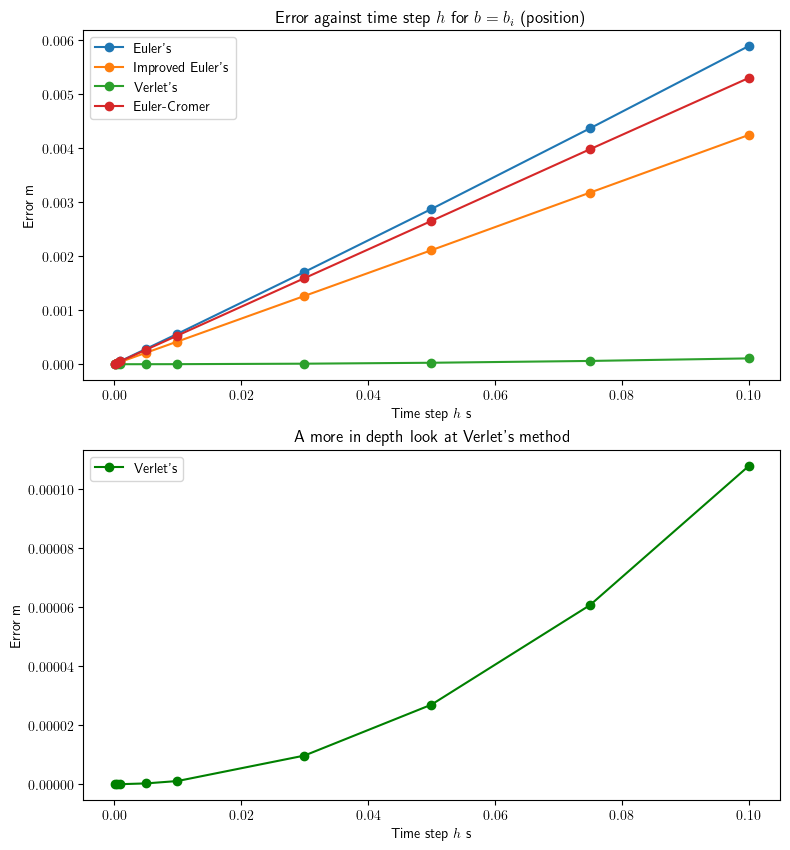

In [19]:
# Plot of the errors found via position against time step h.
plt.rcParams["figure.figsize"] = (9,10)
fig, (ax1, ax2) = plt.subplots(2, 1)

ax1.plot(h_values, x_eul_sigmas_h_b_i, label="Euler's", linestyle='-', marker='o')
ax1.plot(h_values, x_imp_sigmas_h_b_i, label="Improved Euler's", linestyle='-', marker='o')
ax1.plot(h_values, x_ver_sigmas_h_b_i, label="Verlet's", linestyle='-', marker='o')
ax1.plot(h_values, x_crom_sigmas_h_b_i, label="Euler-Cromer", linestyle='-', marker='o')

ax1.set(xlabel=r"Time step $h$ s")
ax1.set(ylabel="Error m")
ax1.set_title(r"Error against time step $h$ for $b = b_i$ (position)", fontsize=12)
ax1.legend()

ax2.plot(h_values, x_ver_sigmas_h_b_i, "g", label="Verlet's", linestyle='-', marker='o')
ax2.set(xlabel=r"Time step $h$ s")
ax2.set(ylabel="Error m")
ax2.set_title("A more in depth look at Verlet's method", fontsize=12)
ax2.legend()

plt.show()

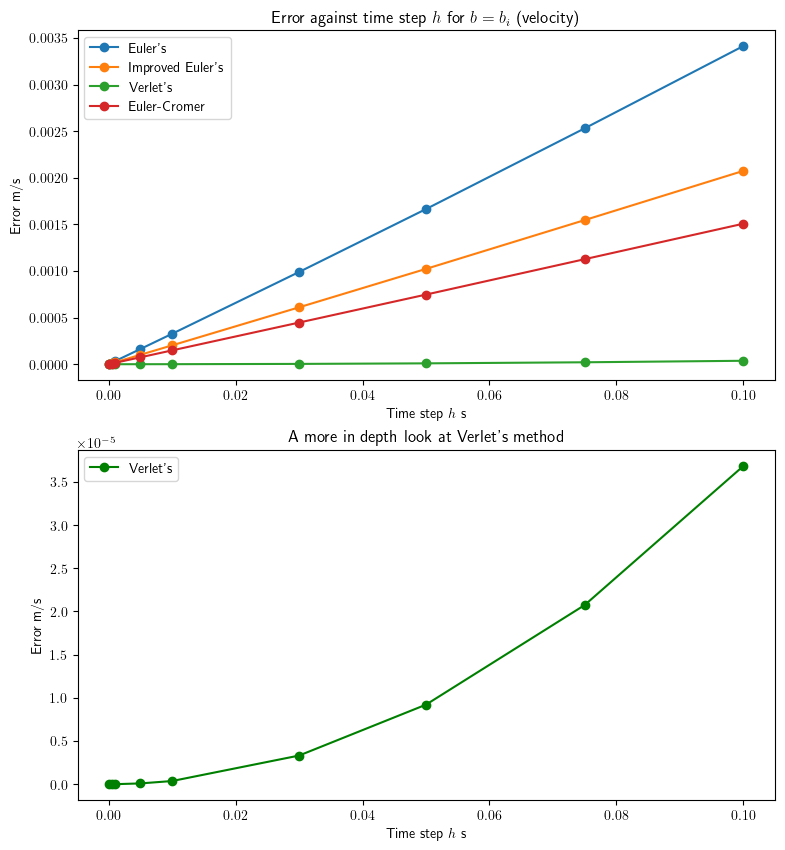

In [20]:
# Plot of errors found via velocity.
plt.rcParams["figure.figsize"] = (9,10)
fig, (ax1, ax2) = plt.subplots(2, 1)

# Position plot.
ax1.plot(h_values, v_eul_sigmas_h_b_i, label="Euler's", linestyle='-', marker='o')
ax1.plot(h_values, v_imp_sigmas_h_b_i, label="Improved Euler's", linestyle='-', marker='o')
ax1.plot(h_values, v_ver_sigmas_h_b_i, label="Verlet's", linestyle='-', marker='o')
ax1.plot(h_values, v_crom_sigmas_h_b_i, label="Euler-Cromer", linestyle='-', marker='o')

ax1.set(xlabel=r"Time step $h$ s ")
ax1.set(ylabel="Error m/s")
ax1.set_title(r"Error against time step $h$ for $b = b_i$ (velocity)", fontsize=12)
ax1.legend()

ax2.plot(h_values, v_ver_sigmas_h_b_i, "g", label="Verlet's", linestyle='-', marker='o')
ax2.set(xlabel=r"Time step $h$ s")
ax2.set(ylabel="Error m/s")
ax2.set_title("A more in depth look at Verlet's method", fontsize=12)
ax2.legend()

plt.show()

From above we can see that for light damping Verlet's method is much more accurate than the other numerical methods. Also that the error of Verlet's is associated to a higher order of $h^n$ whereas the other methods seem to be of first order. Let us investigate further.

We can broadly estimate a relation between the errors and the time step as below:

$\sigma = ch^n$, where $c$ is a pre factor depending on initial conditions, parameters and differing for the individual methods.

$n$ is the order of which the errors depend on $h$. If we plot a log curve we will be able to see the approximate orders of $h$ for the different methods. It is important to note that these orders may differ for position and velocity of the same method, as they can/often have different local errors.

$\log(\sigma) = \log(c) + n\log(h)$

In [21]:
# Compute the logarithms of the values.
log_h_values = np.log(h_values)

# Position.
log_x_eul_sigmas_h_b_i = np.log(x_eul_sigmas_h_b_i)
log_x_imp_sigmas_h_b_i = np.log(x_imp_sigmas_h_b_i)
log_x_ver_sigmas_h_b_i = np.log(x_ver_sigmas_h_b_i)
log_x_crom_sigmas_h_b_i = np.log(x_crom_sigmas_h_b_i)

# Velocity.
log_v_eul_sigmas_h_b_i = np.log(v_eul_sigmas_h_b_i)
log_v_imp_sigmas_h_b_i = np.log(v_imp_sigmas_h_b_i)
log_v_ver_sigmas_h_b_i = np.log(v_ver_sigmas_h_b_i)
log_v_crom_sigmas_h_b_i = np.log(v_crom_sigmas_h_b_i)

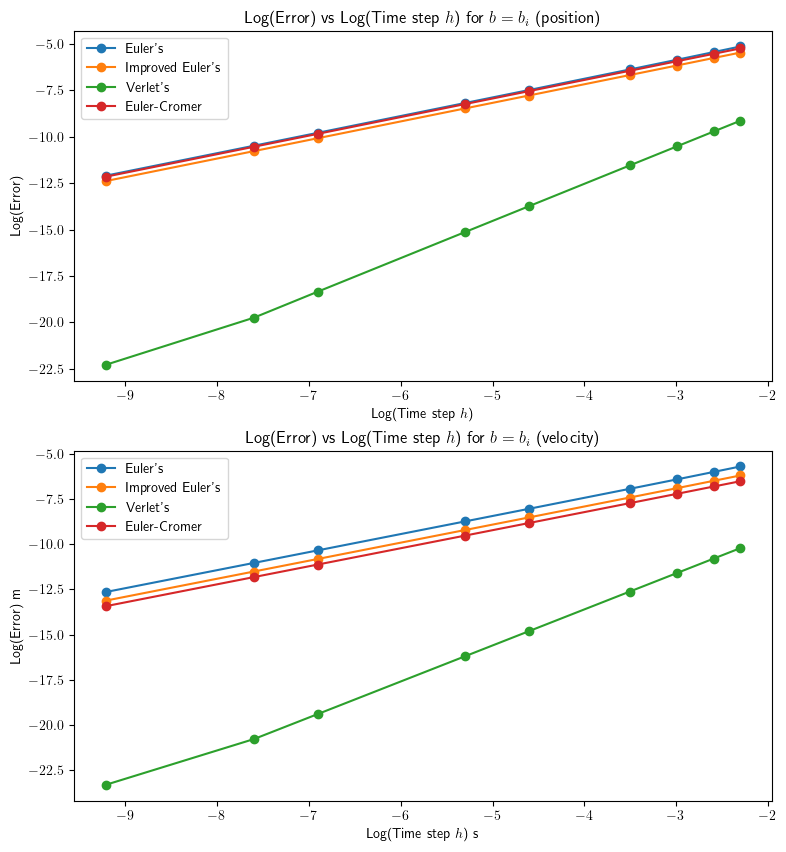

In [22]:
# Plot of the logs of the errors found against the log of the time step h.
plt.rcParams["figure.figsize"] = (9,10)
fig, (ax1, ax2) = plt.subplots(2, 1)

# Position plot.
ax1.plot(log_h_values, log_x_eul_sigmas_h_b_i, label="Euler's", linestyle='-', marker='o')
ax1.plot(log_h_values, log_x_imp_sigmas_h_b_i, label="Improved Euler's", linestyle='-', marker='o')
ax1.plot(log_h_values, log_x_ver_sigmas_h_b_i, label="Verlet's", linestyle='-', marker='o')
ax1.plot(log_h_values, log_x_crom_sigmas_h_b_i, label="Euler-Cromer", linestyle='-', marker='o')

ax1.set(xlabel=r"Log(Time step $h$) ")
ax1.set(ylabel="Log(Error)")
ax1.set_title(r"Log(Error) vs Log(Time step $h$) for $b = b_i$ (position)", fontsize=12)
ax1.legend()

# Velocity plot.
ax2.plot(log_h_values, log_v_eul_sigmas_h_b_i, label="Euler's", linestyle='-', marker='o')
ax2.plot(log_h_values, log_v_imp_sigmas_h_b_i, label="Improved Euler's", linestyle='-', marker='o')
ax2.plot(log_h_values, log_v_ver_sigmas_h_b_i, label="Verlet's", linestyle='-', marker='o')
ax2.plot(log_h_values, log_v_crom_sigmas_h_b_i, label="Euler-Cromer", linestyle='-', marker='o')
ax2.set(xlabel=r"Log(Time step $h$) s")
ax2.set(ylabel="Log(Error) m")
ax2.set_title(r"Log(Error) vs Log(Time step $h$) for $b = b_i$ (velocity)", fontsize=12)
ax2.legend()

plt.show()

From this plot we can see that Euler's, Improved Euler's & Euler-Cromer all share the same $h$ order. We can see that the Verlet's is of a higher order but how high?

We can also see that there is a slight deviation from a straight line for Verlets at smaller $h$ values, the reason for which I am not sure. However we can still find the gradient of the line and therefore the order of the dependence on $h$.

In [23]:
# Perform linear fits to find gradients for position.
slope_x_eul, _ = np.polyfit(log_h_values, log_x_eul_sigmas_h_b_i, 1)
slope_x_imp, _ = np.polyfit(log_h_values, log_x_imp_sigmas_h_b_i, 1)
slope_x_ver, _ = np.polyfit(log_h_values, log_x_ver_sigmas_h_b_i, 1)
slope_x_crom, _ = np.polyfit(log_h_values, log_x_crom_sigmas_h_b_i, 1)

# Perform linear fits to find gradients for velocity.
slope_v_eul, _ = np.polyfit(log_h_values, log_v_eul_sigmas_h_b_i, 1)
slope_v_imp, _ = np.polyfit(log_h_values, log_v_imp_sigmas_h_b_i, 1)
slope_v_ver, _ = np.polyfit(log_h_values, log_v_ver_sigmas_h_b_i, 1)
slope_v_crom, _ = np.polyfit(log_h_values, log_v_crom_sigmas_h_b_i, 1)

# Print the gradients/orders
print("Gradients/orders for Position Errors:")
print(f"Euler's Method: {slope_x_eul:.4f}")
print(f"Improved Euler's Method: {slope_x_imp:.4f}")
print(f"Verlet's Method: {slope_x_ver:.4f}")
print(f"Euler-Cromer Method: {slope_x_crom:.4f}")

print("\nGradients/orders for Velocity Errors:")
print(f"Euler's Method: {slope_v_eul:.4f}")
print(f"Improved Euler's Method: {slope_v_imp:.4f}")
print(f"Verlet's Method: {slope_v_ver:.4f}")
print(f"Euler-Cromer Method: {slope_v_crom:.4f}")

Gradients/orders for Position Errors:
Euler's Method: 1.0061
Improved Euler's Method: 1.0014
Verlet's Method: 1.9415
Euler-Cromer Method: 0.9998

Gradients/orders for Velocity Errors:
Euler's Method: 1.0062
Improved Euler's Method: 1.0036
Verlet's Method: 1.9378
Euler-Cromer Method: 1.0023


These gradients confirm that the Euler, Improved Euler & the Euler-Cromer have an error related to time step $h$ of first order.

These make sense as the lowest local error for all of these methods is $O(h^2)$ and we can multiply by $T/h$ to find a global error of first order. In this case clearly the lower local errors restrict the higher order local errors.

The gradients for Verlet's method are close to two, which indicates they have an error related to time step $h$ of (approximately) second order.

We can see this is between the local errors $O(h^4)$ and $O(h^2)$ when divided by $h$ to find the global error. This will be discussed more later. 

For the best method, Verlet's, lets plot the solutions for $b = b_i$.

In [24]:
# Extract the solutions for Verlets.
x_ver_b_i, v_ver_b_i, t_ver_b_i = verlets_method(0.001, 50, 2, 0, b_i)
# Extract the analytical solutions.
x_an_b_i, v_an_b_i, t_an_b_i = analytical_solutions(0.001, 50, 2, 0, b_i)

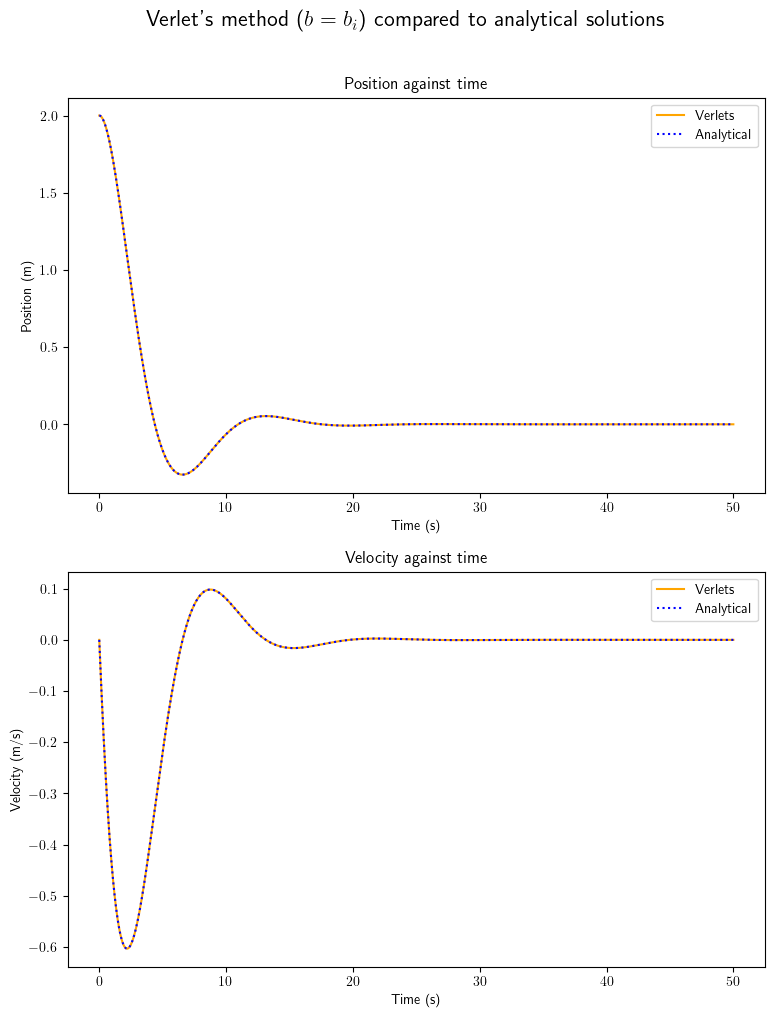

In [25]:
# Plot the solutions found from the Verlet's method with the analytical solutions.
plt.rcParams["figure.figsize"] = (9,11)
fig,(ax1,ax2) = plt.subplots(2,1)
fig.suptitle(r"Verlet's method ($b = b_i$) compared to analytical solutions", fontsize=16)
fig.subplots_adjust(top=0.9)  # Adjust space for the title.

# Position plot.
ax1.plot(t_ver_b_i, x_ver_b_i, "orange", label="Verlets")
ax1.plot(t_an_b_i, x_an_b_i, "b:", label="Analytical")
ax1.set(xlabel="Time (s)")
ax1.set(ylabel="Position (m)")
ax1.set_title("Position against time", fontsize=12)
ax1.legend()

# Velocity plot.
ax2.plot(t_ver_b_i, v_ver_b_i, "orange", label="Verlets")
ax2.plot(t_an_b_i, v_an_b_i, "b:", label="Analytical")
ax2.set(xlabel="Time (s)")
ax2.set(ylabel="Velocity (m/s)")
ax2.set_title("Velocity against time", fontsize=12)
ax2.legend()

As we can see graphically it is a perfect approximation and what we'd expect physically.

### 2.4 (Pos & Vel) ii) critical damping

CRITICAL Damping. Let us find the error for methods at different h values for $b = b_{crit}$, $x_0 = 2$m & $v_0 = 0$m/s.

Orders of error are not discussed as it is trivially similar to section 2.3.

In [26]:
# Extracting the errors for the numerical methods for both positon & velocity for critical damping.
# Note runtime is quite long due to the many h values looked at and the small size of some of them.
pos_sigmas_h_b_crit, vel_sigmas_h_b_crit = err(50, 2, 0, b_crit) 

In [27]:
# Extracting the errors for each numerical method for position.
x_eul_sigmas_h_b_crit = pos_sigmas_h_b_crit[:, 0]
x_imp_sigmas_h_b_crit = pos_sigmas_h_b_crit[:, 1]
x_ver_sigmas_h_b_crit = pos_sigmas_h_b_crit[:, 2]
x_crom_sigmas_h_b_crit = pos_sigmas_h_b_crit[:, 3]

# Extracting the errors for each numerical method for velocity.
v_eul_sigmas_h_b_crit = vel_sigmas_h_b_crit[:, 0]
v_imp_sigmas_h_b_crit = vel_sigmas_h_b_crit[:, 1]
v_ver_sigmas_h_b_crit = vel_sigmas_h_b_crit[:, 2]
v_crom_sigmas_h_b_crit = vel_sigmas_h_b_crit[:, 3]

# We now have an array for each method, with the length of the (no. h values). Below we can define the h_values we used, as an array.
# This will be useful for when we plot the errors against the h values.

h_values = np.array([0.0001, 0.0005, 0.001, 0.005, 0.01, 0.03, 0.05, 0.075, 0.1])

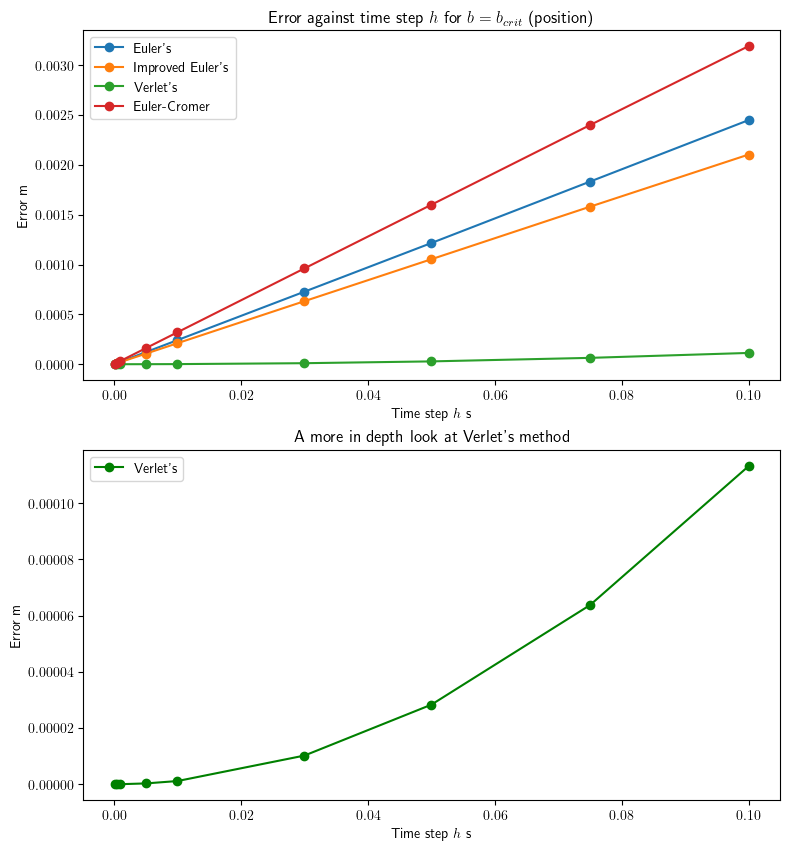

In [28]:
# Plot of the errors found via position.
plt.rcParams["figure.figsize"] = (9,10)
fig, (ax1, ax2) = plt.subplots(2, 1)

# Position plot.
ax1.plot(h_values, x_eul_sigmas_h_b_crit, label="Euler's", linestyle='-', marker='o')
ax1.plot(h_values, x_imp_sigmas_h_b_crit, label="Improved Euler's", linestyle='-', marker='o')
ax1.plot(h_values, x_ver_sigmas_h_b_crit, label="Verlet's", linestyle='-', marker='o')
ax1.plot(h_values, x_crom_sigmas_h_b_crit, label="Euler-Cromer", linestyle='-', marker='o')

ax1.set(xlabel=r"Time step $h$ s")
ax1.set(ylabel="Error m")
ax1.set_title(r"Error against time step $h$ for $b = b_{crit}$ (position)", fontsize=12)
ax1.legend()

ax2.plot(h_values, x_ver_sigmas_h_b_crit, "g", label="Verlet's", linestyle='-', marker='o')
ax2.set(xlabel=r"Time step $h$ s")
ax2.set(ylabel="Error m")
ax2.set_title("A more in depth look at Verlet's method", fontsize=12)
ax2.legend()

plt.show()

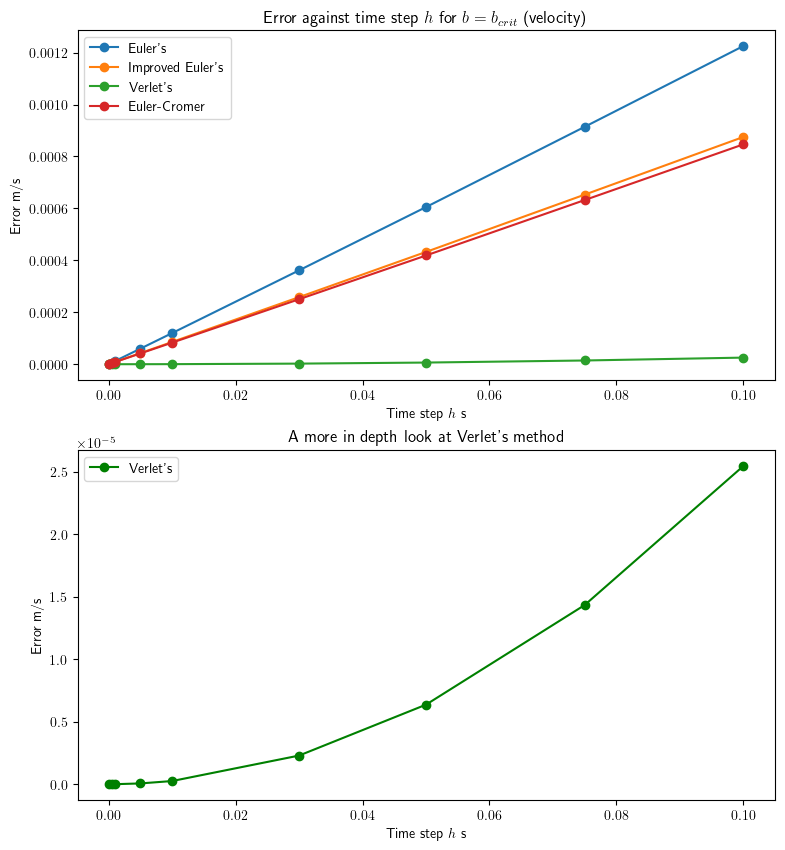

In [29]:
# Plot of errors found via velocity.
plt.rcParams["figure.figsize"] = (9,10)
fig, (ax1, ax2) = plt.subplots(2, 1)

# Position plot.
ax1.plot(h_values, v_eul_sigmas_h_b_crit, label="Euler's", linestyle='-', marker='o')
ax1.plot(h_values, v_imp_sigmas_h_b_crit, label="Improved Euler's", linestyle='-', marker='o')
ax1.plot(h_values, v_ver_sigmas_h_b_crit, label="Verlet's", linestyle='-', marker='o')
ax1.plot(h_values, v_crom_sigmas_h_b_crit, label="Euler-Cromer", linestyle='-', marker='o')

ax1.set(xlabel=r"Time step $h$ s ")
ax1.set(ylabel="Error m/s")
ax1.set_title(r"Error against time step $h$ for $b = b_{crit}$ (velocity)", fontsize=12)
ax1.legend()

ax2.plot(h_values, v_ver_sigmas_h_b_crit, "g", label="Verlet's", linestyle='-', marker='o')
ax2.set(xlabel=r"Time step $h$ s")
ax2.set(ylabel="Error m/s")
ax2.set_title("A more in depth look at Verlet's method", fontsize=12)
ax2.legend()

plt.show()

Again Verlet's method is much more accurate.

The switching round of the accuracy of the Euler's, Improved Euler's & Euler-Cromer methods is due to the differing pre factors (conditions).

For the best method, Verlet's, lets plot the solutions for $b = b_{crit}$.

In [30]:
# Extract the solutions for Verlets.
x_ver_b_crit, v_ver_b_crit, t_ver_b_crit = verlets_method(0.001, 50, 2, 0, b_crit)
# Extract the analytical solutions.
x_an_b_crit, v_an_b_crit, t_an_b_crit = analytical_solutions(0.001, 50, 2, 0, b_crit)

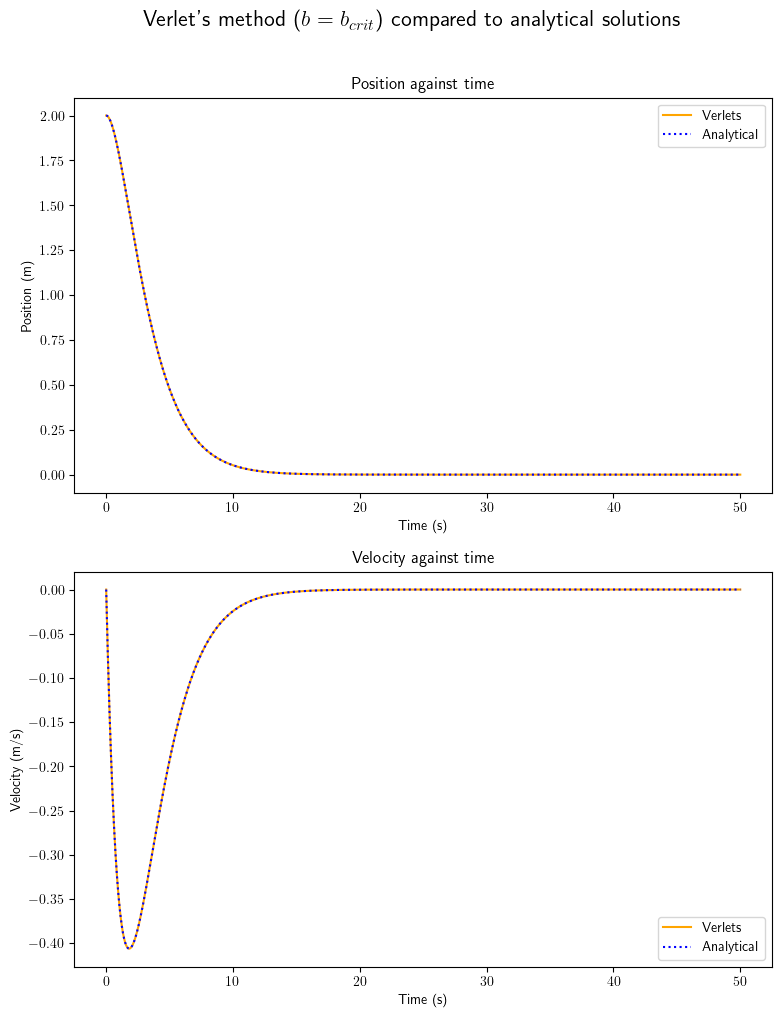

In [31]:
# Plot the solutions found from the Verlet's method with the analytical solutions.
plt.rcParams["figure.figsize"] = (9,11)
fig,(ax1,ax2) = plt.subplots(2,1)
fig.suptitle(r"Verlet's method ($b = b_{crit}$) compared to analytical solutions", fontsize=16)
fig.subplots_adjust(top=0.9)  # Adjust space for the title.

# Position plot.
ax1.plot(t_ver_b_crit, x_ver_b_crit, "orange", label="Verlets")
ax1.plot(t_an_b_crit, x_an_b_crit, "b:", label="Analytical")
ax1.set(xlabel="Time (s)")
ax1.set(ylabel="Position (m)")
ax1.set_title("Position against time", fontsize=12)
ax1.legend()

# Velocity plot.
ax2.plot(t_ver_b_crit, v_ver_b_crit, "orange", label="Verlets")
ax2.plot(t_an_b_crit, v_an_b_crit, "b:", label="Analytical")
ax2.set(xlabel="Time (s)")
ax2.set(ylabel="Velocity (m/s)")
ax2.set_title("Velocity against time", fontsize=12)
ax2.legend()

As we can see it is graphically a perfect approximation and behaves as we'd expect physically, the oscillation returning to equilibrium in the shortest amount of time.

### 2.5 (Pos & Vel) iii) heavy damping

iii) HEAVY damping. Let us find the error for methods at different h values for $b = b_{iii} = 2b_{crit}$, $x_0 = 2$m & $v_0 = 0$m/s.

Orders of error are not discussed as it is trivially similar to section 2.3.

In [32]:
# Extracting the errors for the numerical methods for both positon & velocity for heavy damping.
# Note runtime is quite long due to the many h values looked at and the small size of some of them.
pos_sigmas_h_b_iii, vel_sigmas_h_b_iii = err(50, 2, 0, b_iii) 

In [33]:
# Extracting the errors for each numerical method for position.
x_eul_sigmas_h_b_iii = pos_sigmas_h_b_iii[:, 0]
x_imp_sigmas_h_b_iii = pos_sigmas_h_b_iii[:, 1]
x_ver_sigmas_h_b_iii = pos_sigmas_h_b_iii[:, 2]
x_crom_sigmas_h_b_iii = pos_sigmas_h_b_iii[:, 3]

# Extracting the errors for each numerical method for velocity.
v_eul_sigmas_h_b_iii = vel_sigmas_h_b_iii[:, 0]
v_imp_sigmas_h_b_iii = vel_sigmas_h_b_iii[:, 1]
v_ver_sigmas_h_b_iii = vel_sigmas_h_b_iii[:, 2]
v_crom_sigmas_h_b_iii = vel_sigmas_h_b_iii[:, 3]

# We now have an array for each method, with the length of the (no. h values). Below we can define the h_values we used, as an array.
# This will be useful for when we plot the errors against the h values.

h_values = np.array([0.0001, 0.0005, 0.001, 0.005, 0.01, 0.03, 0.05, 0.075, 0.1])

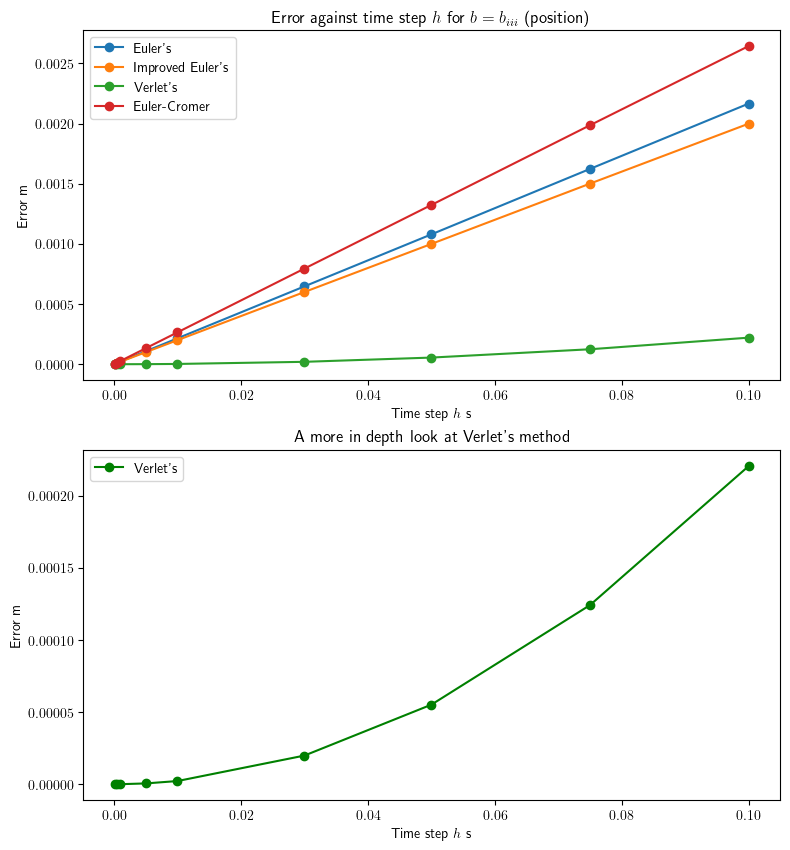

In [34]:
# Plot of the errors found via position.
plt.rcParams["figure.figsize"] = (9,10)
fig, (ax1, ax2) = plt.subplots(2, 1)

# Position plot.
ax1.plot(h_values, x_eul_sigmas_h_b_iii, label="Euler's", linestyle='-', marker='o')
ax1.plot(h_values, x_imp_sigmas_h_b_iii, label="Improved Euler's", linestyle='-', marker='o')
ax1.plot(h_values, x_ver_sigmas_h_b_iii, label="Verlet's", linestyle='-', marker='o')
ax1.plot(h_values, x_crom_sigmas_h_b_iii, label="Euler-Cromer", linestyle='-', marker='o')

ax1.set(xlabel=r"Time step $h$ s")
ax1.set(ylabel="Error m")
ax1.set_title(r"Error against time step $h$ for $b = b_{iii}$ (position)", fontsize=12)
ax1.legend()

ax2.plot(h_values, x_ver_sigmas_h_b_iii, "g", label="Verlet's", linestyle='-', marker='o')
ax2.set(xlabel=r"Time step $h$ s")
ax2.set(ylabel="Error m")
ax2.set_title("A more in depth look at Verlet's method", fontsize=12)
ax2.legend()

plt.show()

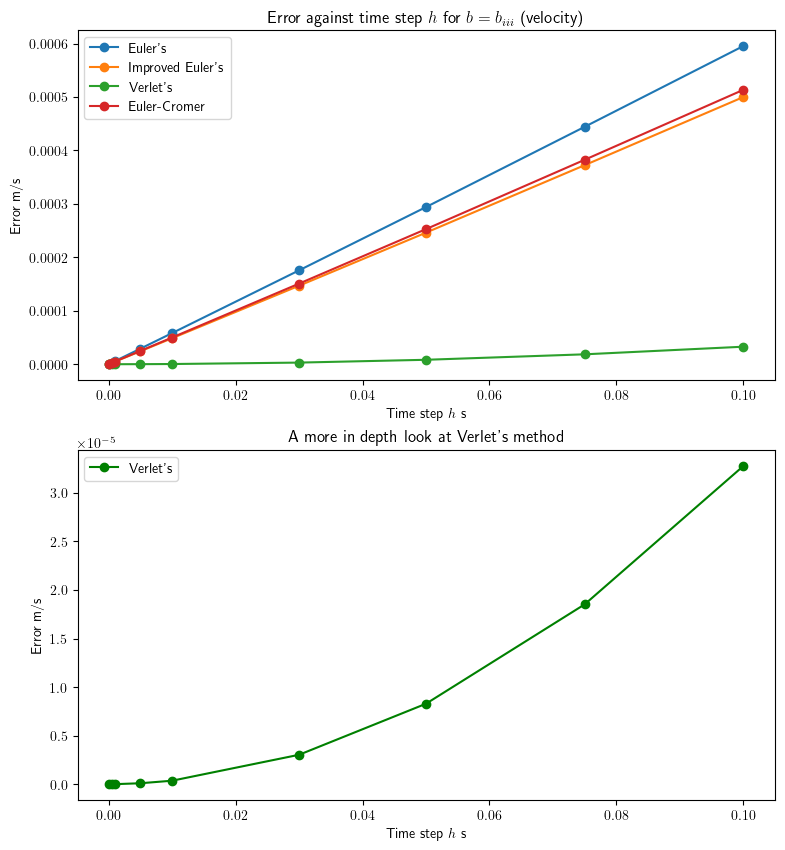

In [35]:
# Plot of the errors found via position.
plt.rcParams["figure.figsize"] = (9,10)
fig, (ax1, ax2) = plt.subplots(2, 1)

# Position plot.
ax1.plot(h_values, v_eul_sigmas_h_b_iii, label="Euler's", linestyle='-', marker='o')
ax1.plot(h_values, v_imp_sigmas_h_b_iii, label="Improved Euler's", linestyle='-', marker='o')
ax1.plot(h_values, v_ver_sigmas_h_b_iii, label="Verlet's", linestyle='-', marker='o')
ax1.plot(h_values, v_crom_sigmas_h_b_iii, label="Euler-Cromer", linestyle='-', marker='o')

ax1.set(xlabel=r"Time step $h$ s")
ax1.set(ylabel="Error m/s")
ax1.set_title(r"Error against time step $h$ for $b = b_{iii}$ (velocity)", fontsize=12)
ax1.legend()

ax2.plot(h_values, v_ver_sigmas_h_b_iii, "g", label="Verlet's", linestyle='-', marker='o')
ax2.set(xlabel=r"Time step $h$ s")
ax2.set(ylabel="Error m/s")
ax2.set_title("A more in depth look at Verlet's method", fontsize=12)
ax2.legend()

plt.show()

Again Verlet's is the most accurate by a lot.

And again the switching round of the accuracy of the Euler's, Improved Euler's & Euler-Cromer methods is due to the differing pre factors (conditions).

For the best method, Verlet's, lets plot the solutions for $b = b_{iii}$.

In [36]:
# Extract the solutions for Verlets.
x_ver_b_iii, v_ver_b_iii, t_ver_b_iii = verlets_method(0.001, 50, 2, 0, b_iii)
# Extract the analytical solutions.
x_an_b_iii, v_an_b_iii, t_an_b_iii = analytical_solutions(0.001, 50, 2, 0, b_iii)

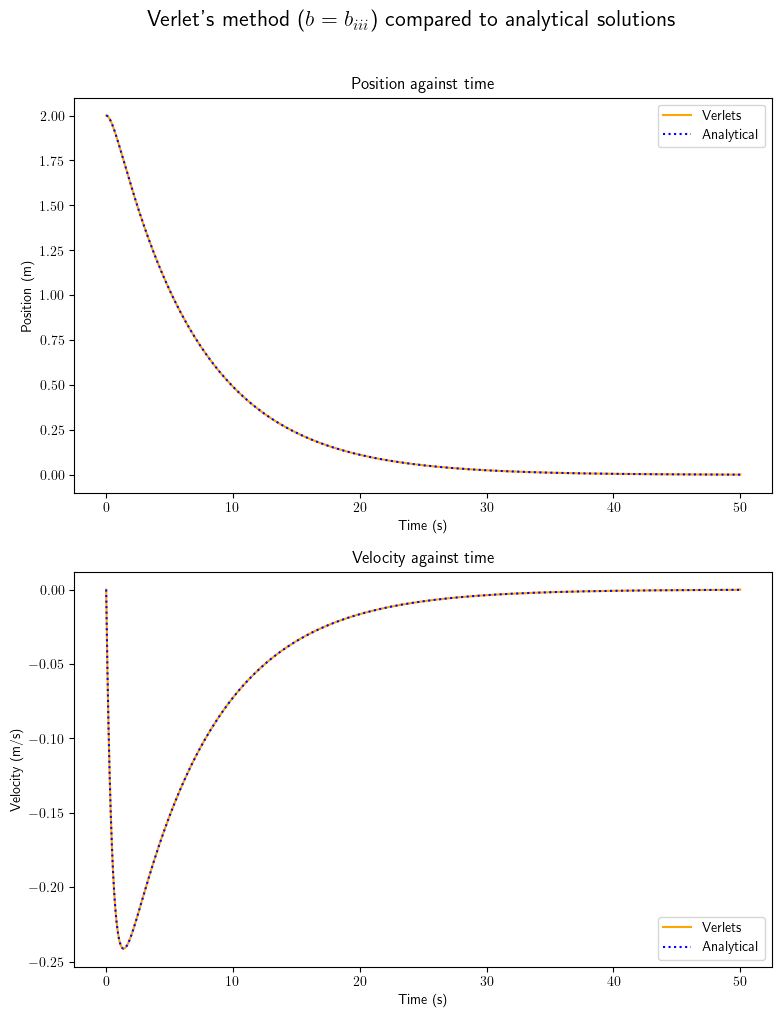

In [37]:
# Plot the solutions found from the Verlet's method with the analytical solutions.
plt.rcParams["figure.figsize"] = (9,11)
fig,(ax1,ax2) = plt.subplots(2,1)
fig.suptitle(r"Verlet's method ($b = b_{iii}$) compared to analytical solutions", fontsize=16)
fig.subplots_adjust(top=0.9)  # Adjust space for the title.

# Position plot.
ax1.plot(t_ver_b_iii, x_ver_b_iii, "orange", label="Verlets")
ax1.plot(t_an_b_iii, x_an_b_iii, "b:", label="Analytical")
ax1.set(xlabel="Time (s)")
ax1.set(ylabel="Position (m)")
ax1.set_title("Position against time", fontsize=12)
ax1.legend()

# Velocity plot.
ax2.plot(t_ver_b_iii, v_ver_b_iii, "orange", label="Verlets")
ax2.plot(t_an_b_iii, v_an_b_iii, "b:", label="Analytical")
ax2.set(xlabel="Time (s)")
ax2.set(ylabel="Velocity (m/s)")
ax2.set_title("Velocity against time", fontsize=12)
ax2.legend()

As we can see graphically it is a perfect approximation and acts as we'd expect heavy damping to do so.

### 2.6 Investigating Verlet's further

As Verlet's method is clearly the more accurate method I wish to investigate it further. The function below does so.

In [38]:
def verlet_err(T, x_0, v_0, b):
    """
    T is the time we are integrating until, in seconds.
    x_0 is the initial condition for position.
    v_0 is the initial condition for velocity.
    b is the damping constant. Typically either b_i, b_crit, or b_iii

    h is the step size in seconds. It is varied, taking the values from h_values.

    This function finds the error between the verlet method and the analytical solution using the mean absolute error.
    It find this for all the h values specified.
    """
    
    #h_values = np.array([0.0001, 0.0005, 0.001, 0.005, 0.01, 0.03, 0.05, 0.075, 0.1])

    h_values = np.arange(0.0001, 0.01, 0.001) # Investigate these h values mostly.

    # These h values below are small and inserted. Due to there small step size they take a long time to run.
    # I want these to demonstrate that when h gets too small the error starts to increase.
    # Only kept one to keep runtime lower but still to demonstrate. Uncomment if you wish to see others.
    h_values = np.insert(h_values, 0, 0.00001)

    #h_values = np.insert(h_values, 1, 0.000018)

    #h_values = np.insert(h_values, 2, 0.00002)

    #h_values = np.insert(h_values, 3, 0.00005)

    # Creating arrays/matrix to put the errors in.
    x_ver_sigmas_h = np.zeros(len(h_values))
    v_ver_sigmas_h = np.zeros(len(h_values))

    # Iterating through the different h values
    for i, h in enumerate(h_values):

        # Defing the solutions for a certain h value.
        x_an, v_an, t = analytical_solutions(h, T, x_0, v_0, b)

        x_ver, v_ver, _ = verlets_method(h, T, x_0, v_0, b)

        # Again finding the MAE of position and velocity. In this case only for verlets.
        x_sum_error = np.sum(np.abs(x_ver - x_an))
        x_N = len(x_ver)
        x_ver_sigmas_h[i] = x_sum_error / x_N

        v_sum_error = np.sum(np.abs(v_ver - v_an))
        v_N = len(v_ver)
        v_ver_sigmas_h[i] = v_sum_error / v_N

    # Plot of the errors against h value.
    plt.rcParams["figure.figsize"] = (9,10)
    fig, (ax1, ax2) = plt.subplots(2, 1)
    
    # Position plot.
    ax1.plot(h_values, x_ver_sigmas_h, "x")
    ax1.set(xlabel=r"Time step $h$ s")
    ax1.set(ylabel="Error m")
    ax1.set_title(r"Error against time step $h$ (position)", fontsize=12)
    
    ax2.plot(h_values, v_ver_sigmas_h, "x")
    ax2.set(xlabel=r"Time step $h$ s")
    ax2.set(ylabel="Error m/s")
    ax2.set_title("Error against time step $h$ (velocity)", fontsize=12)
    
    plt.show()

    return x_ver_sigmas_h, v_ver_sigmas_h

The above function investigates the relationship between error and step size $h$ for Verlet's method in more detail.

It looks more closely at the low $h$ values we've already plotted but weren't very clear as they were very small. Unlike previously it shows after a certain point, $h$ decreasing no longer causes the error to decrease. In fact  it causes it to increase.

Due to the small h values used, the below markdown takes a while to run. I only used one $h$ value that causes an unexpected increase in error (not following $h^2$) to limit runtime. If you wish to see others just uncomment them in the function.

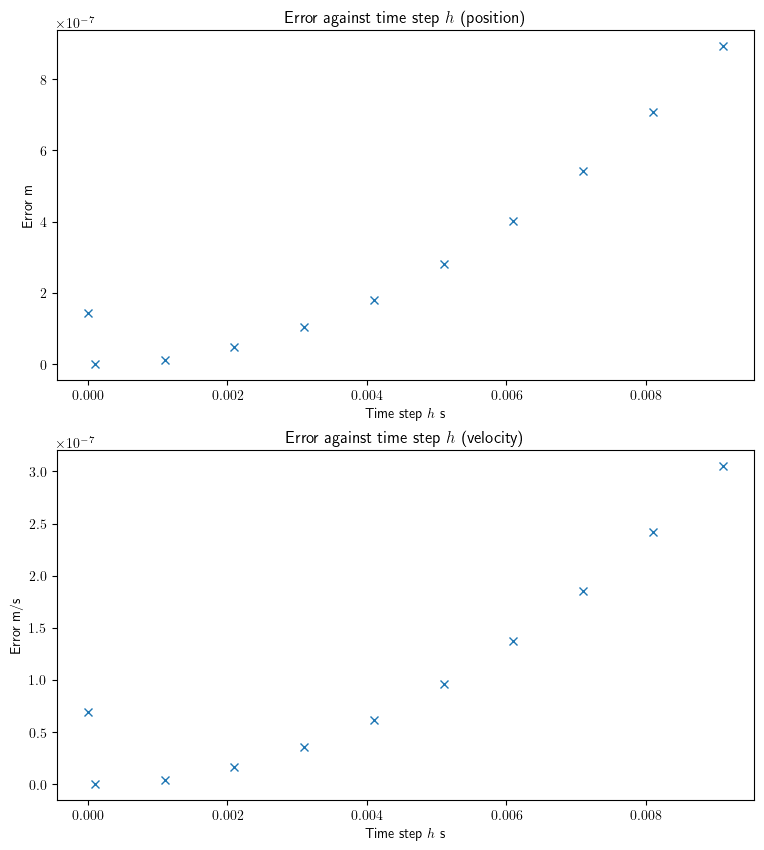

In [39]:
_, _= verlet_err(50, 2, 0, b_i)
# Note Long run time as we are computing for very small time steps to find their effects.

Again we can see the global error is related to $h^2$.

From this plot we can see that the trend, as $h$ gets smaller so does the error, is broken at a certain $h$ values. This is due to the computer making round off errors for very small numbers. In this case the optimum $h$ value is around $h = 0.0001$.

Further investigation of Verlet's method is in the stretch yourself section 4.1. Reading this before section 3 may be preferred.

## 3. Investigation of an external force applied ($F(t) \neq 0$)

In this section I intend to numerically investigate a spring-mass system which is subjected to an external force $F(t)$. I will use the most accurate method, Verlet's. I would use the time step of $h = 0.0001$ as this is just before the turning point where decreasing $h$ no longer decreases error. However this takes a long time to run so instead I will use $h = 0.001$ which is still very accurate and doesn't have as long runtimes.

$m\ddot{x} + b\dot{x} + kx = ma(t) + bv(t) + kx(t) = F(t)$.

Starting from here again we can find the Verlet's method with an external force $F(t_i) = F_i$. Therefore $a_i$ has an extra term. 

$x_{i+1} = 2x_i - x_{i-1} + h^2 a_i$

$a_i = \frac{F_i}{m} -\frac{k}{m} x_i - \frac{b}{m} v_i$

$v_i = \frac{x_{i+1} - x_{i-1}}{2h}$

Using the same method as last time we find:

$x_{i+1} = A x_i + B x_{i-1} + CF_i$,

where $A = 2 \frac{(2m - k h^2)}{D}, \quad B = \frac{(b h - 2m)}{D}, \quad C = \frac{2h^2}{D}  \quad D = 2m + b h$.

Below I will define a function that incorporates the external force into the Verlet's method.

### 3.1 Forced Push

In [40]:
def verlets_method_F_push(h, T, x_0, v_0, b, F_t_start, F_t_end, F_amp):
    """
    h is the step size in seconds.
    T is the time we are integrating until, in seconds.
    x_0 is the initial condition for position.
    v_0 is the initial condition for velocity.
    b is the damping constant.

    F_t_start is the time (s) at which the force/push is first applied. Should be after a few oscillation.
    F_t_end is the time (s) at which the force/push is no longer applied.
    Originally I used the indices surrounding a single push time. However after discussion with demonstrator this is inappropiate as is too dependent on step size.
    Using a start and end time for the push has no downsides.
    
    F_amp is the amplitude of the force applied in N. This holds the direction at which it is applied also.

    This function uses the equations in the above markdown to carry out Verlet's numerical method with the application of an external force (as a push).

    For the first step it must use another method as discussed in the above markdown. Improved euler's is used here for more accuracy.

    It returns the arrays of position, velocity & time.
    """
    
    no_steps = int(T/h) # Determine how many whole number steps are within T. Each step is one i.

    t = np.arange(0, (no_steps * h), h) # Define time intervals for each step. Useful for when we plot.
    
    x = np.zeros(no_steps) # Empty array for position.
    v = np.zeros(no_steps) # Empty array for velocity.

    F = np.zeros(no_steps) # Empty array for external force.
    
    # This finds the index of the time array for F_t_start & F_t_end.
    # It does so by finding the shortest time between F_t_start/F_t_end and a value of the t array.
    start_ind = np.argmin(np.abs(t - F_t_start))
    end_ind = np.argmin(np.abs(t - F_t_end))
    # It is done like this as the time array is discrete. 

    # Adding this force to the indices corresponding to F_t_start/F_t_end.
    F[start_ind:end_ind] = F_amp
    
    # Use the initial conditions from the function arguments.
    x[0] = x_0
    v[0] = v_0
    
    D = 2 * m + b * h

    A =  2 * (2 * m - k * h**2) / D

    B = (b * h - 2 * m) / D

    C = 2 * h**2 / D # Extra term for external force.

    # Use improved euler's method to find (i) from (i - 1)

    # Using x_0 / x[0] as (i - 1) and x_1 / x[1] as (i) for example.

    a_0 = (F[0] / m) - (k / m) * x[0] - (b / m) * v[0] # Acceleration at step (i - 1). In the push case F[0] will be 0.

    x[1] = x_1 = x[0] + h * v[0] + h**2 * a_0 / 2
    v[1] = v_1 = v[0] + h * a_0

    

    for i in range(1, no_steps - 1): # The first argument in range starts the for loop at index 1 (i). If we started from index 0 we would not be able to access (i - 1).

        x[i+1] = (A * x[i]) + (B * x[i-1]) + (C * F[i]) # F[i added for the forced case.

        v[i] = (x[i+1] - x[i-1]) / (2 * h) # Incase we are interested in velocity. Although we'll have one less term.

    return x, v, t

Let us investigate how a $1$N push for $1$ second at $t = 50$s effects the nature of light damping $b = b_1$ with initial conditions $x_0 = 2$m $v_0 = 0$m/s.

In [41]:
# Extracting the data for a 1N push between 50s & 51s.
x_push1, v_push1, t_push1 = verlets_method_F_push(0.001, 221, 2, 0, b_1, 50, 51, 1)

In [42]:
# Extracting the analytical solution for these initial conditions but without any push.
x_an_npush1, v_an_npush1, t_an_npush1 = analytical_solutions(0.001, 221, 2, 0, b_1)
# The npush is to show the analytical solution isn't actually for a push.

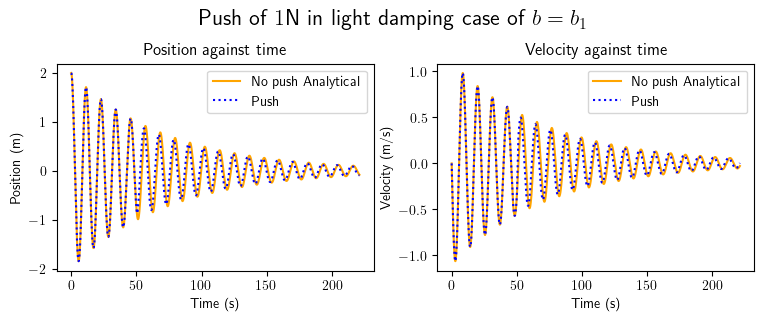

In [43]:
# Plot these results.
plt.rcParams["figure.figsize"] = (9,3)
fig,(ax1,ax2) = plt.subplots(1,2)
fig.suptitle(r"Push of $1$N in light damping case of $b = b_1$", fontsize=16)
fig.subplots_adjust(top=0.8)  # Adjust space for the title.

# Position plot.
ax1.plot(t_an_npush1, x_an_npush1, "orange", label="No push Analytical")
ax1.plot(t_push1, x_push1, "b:", label="Push")
ax1.set(xlabel="Time (s)")
ax1.set(ylabel="Position (m)")
ax1.set_title("Position against time", fontsize=12)
ax1.legend()


# Velocity plot.
ax2.plot(t_an_npush1[:-1], v_an_npush1[:-1], "orange", label="No push Analytical")
ax2.plot(t_push1[:-1], v_push1[:-1], "b:", label="Push")
# Use of [:-1] to remove the last element in the velocity arrays. As the verlet method returns one less term for velocity.
ax2.set(xlabel="Time (s)")
ax2.set(ylabel="Velocity (m/s)")
ax2.set_title("Velocity against time", fontsize=12)
ax2.legend()

The drop in amplitude (loss in energy) makes sense here, as the force applied at $50$s is opposing the motion.

If we applied the same force but in the oppisite direction we should see an increase in amplitude (gain in energy).
All we need to change is $F_{amp}$ to $-1$N.

In [44]:
# Extracting the data for a -1N push between 50s & 51s.
x_push2, v_push2, t_push2 = verlets_method_F_push(0.001, 221, 2, 0, b_1, 50, 51, -1)
# We can use the same analytical solutions, as we have only altered the push.

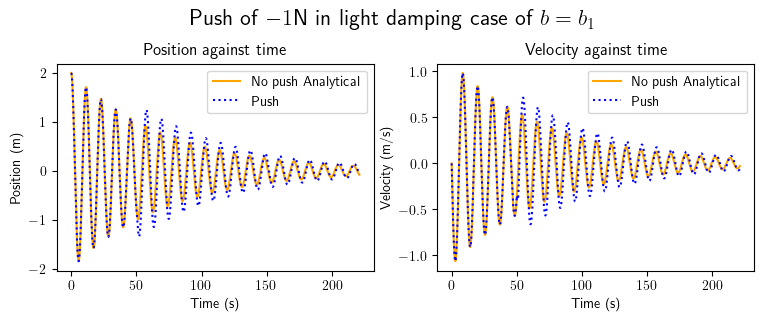

In [45]:
# Plot the results.
plt.rcParams["figure.figsize"] = (9,3)
fig,(ax1,ax2) = plt.subplots(1,2)
fig.suptitle(r"Push of $-1$N in light damping case of $b = b_1$", fontsize=16)
fig.subplots_adjust(top=0.8)  # Adjust space for the title.

# Position plot.
ax1.plot(t_an_npush1, x_an_npush1, "orange", label="No push Analytical")
ax1.plot(t_push2, x_push2, "b:", label="Push")
ax1.set(xlabel="Time (s)")
ax1.set(ylabel="Position (m)")
ax1.set_title("Position against time", fontsize=12)
ax1.legend()


# Velocity plot.
ax2.plot(t_an_npush1[:-1], v_an_npush1[:-1], "orange", label="No push Analytical")
ax2.plot(t_push2[:-1], v_push2[:-1], "b:", label="Push")
# Use of [:-1] to remove the last element in the velocity arrays. As the verlet method returns one less term for velocity.
ax2.set(xlabel="Time (s)")
ax2.set(ylabel="Velocity (m/s)")
ax2.set_title("Velocity against time", fontsize=12)
ax2.legend()

As we can see the force being applied in the direction of motion does increase the amplitude of the oscillation.

We can also see that the pushes cause a shift in phase compared to the no push analytical solution. When the force is applied against the direction of motion we see a shift backwards and when applied in the direction of motion we see a shift forwards.

We should also see that if the force $+1$N is applied at a different time, where it is now in the direction of motion, there should be an increase in amplitude.

The same applies for a force $-1$N, if it is applied at a time where it is now against the direction of motion, there should be an decrease in amplitude.

Let us test for $+1$N.

In [46]:
# Extracting the data for a 1N push between 55s & 56s.
x_push3, v_push3, t_push3 = verlets_method_F_push(0.001, 221, 2, 0, b_1, 55, 56, 1)
# Again we can use the same non push analytical solutions.

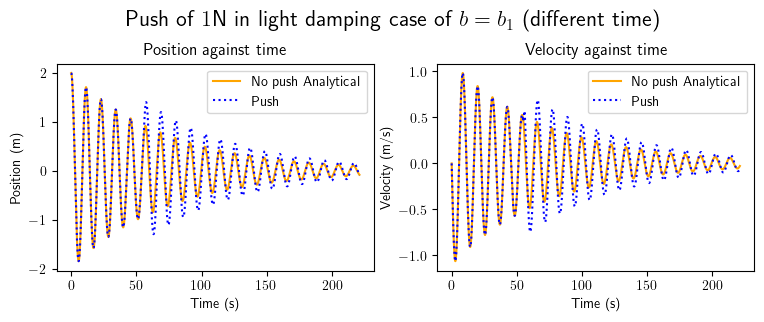

In [47]:
# Plot these results.
plt.rcParams["figure.figsize"] = (9,3)
fig,(ax1,ax2) = plt.subplots(1,2)
fig.suptitle(r"Push of $1$N in light damping case of $b = b_1$ (different time)", fontsize=16)
fig.subplots_adjust(top=0.8)  # Adjust space for the title.

# Position plot.
ax1.plot(t_an_npush1, x_an_npush1, "orange", label="No push Analytical")
ax1.plot(t_push3, x_push3, "b:", label="Push")
ax1.set(xlabel="Time (s)")
ax1.set(ylabel="Position (m)")
ax1.set_title("Position against time", fontsize=12)
ax1.legend()


# Velocity plot.
ax2.plot(t_an_npush1[:-1], v_an_npush1[:-1], "orange", label="No push Analytical")
ax2.plot(t_push3[:-1], v_push3[:-1], "b:", label="Push")
# Use of [:-1] to remove the last element in the velocity arrays. As the verlet method returns one less term for velocity.
ax2.set(xlabel="Time (s)")
ax2.set(ylabel="Velocity (m/s)")
ax2.set_title("Velocity against time", fontsize=12)
ax2.legend()

As expected there was an increase in amplitude when the force was applied in the direction of motion. Interestingly the increase in amplitude is greater than that of our previous increase. Clearly how much the motion is in that direction the greater the resulting amplitude. 

### 3.2 Forced Oscillations

Here the force will be applied sinusoidally with a frequency different from the undamped natural frequency $\omega_0$.

$m\ddot{x} + b\dot{x} + kx = F(t) = F_0 \cos(\Omega t)$, where $\Omega$ is the driving frequency.

In [48]:
def verlets_method_F_oscillations(h, T, x_0, v_0, b, F_0, driv_freq):
    """
    h is the step size in seconds.
    T is the time we are integrating until, in seconds.
    x_0 is the initial condition for position.
    v_0 is the initial condition for velocity.
    b is the damping constant. It is b_1 unless stated otherwise.

    F_0 is the amplitude of the force applied in N. This holds the direction at which it is initially applied.
    driv_freq is the driving frequency.

    This function uses the equations in the above markdown to carry out Verlet's numerical method with the application of an external force (sinusoidally).
    (Above markdown is before section 3.1)

    For the first step it must use another method as discussed in the above markdown. Improved euler's is used here for more accuracy.

    It returns the arrays of position, velocity & time.
    """
    
    no_steps = int(T/h) # Determine how many whole number steps are within T. Each step is one i.

    t = np.arange(0, (no_steps * h), h) # Define time intervals for each step. Useful for when we plot.
    
    x = np.zeros(no_steps) # Empty array for position.
    v = np.zeros(no_steps) # Empty array for velocity.

    F = F_0 * np.cos(driv_freq * t) # Defines the sinusoidal force in an array to be used in verlets method.

    
    # Use the initial conditions from the function arguments.
    x[0] = x_0
    v[0] = v_0
    
    D = 2 * m + b * h

    A =  2 * (2 * m - k * h**2) / D

    B = (b * h - 2 * m) / D

    C = 2 * h**2 / D # Extra term for external force.

    # Use improved euler's method to find (i) from (i - 1)

    # Using x_0 / x[0] as (i - 1) and x_1 / x[1] as (i) for example.

    a_0 = (F[0] / m) - (k / m) * x[0] - (b / m) * v[0] # Acceleration at step (i - 1). In the push case F[0] will be 0.

    x[1] = x_1 = x[0] + h * v[0] + h**2 * a_0 / 2
    v[1] = v_1 = v[0] + h * a_0

    

    for i in range(1, no_steps - 1): # The first argument in range starts the for loop at index 1 (i). If we started from index 0 we would not be able to access (i - 1).

        #print(F[i])
        
        x[i+1] = (A * x[i]) + (B * x[i-1]) + (C * F[i]) # The force included in Verlets.

        v[i] = (x[i+1] - x[i-1]) / (2 * h) # Velocity will have one less term.

    return x, v, t

Let us investigate forced oscillations for damping $b = b_i$, initial conditions $x_0 = 2$m & $v_0 = 0$m/s, $F_0 =  3$N and driving frequency $\Omega = \frac{\omega_0}{2}$.

We should see a short transient period after which the oscillations continue on steadily at the same amplitude.

When comparing to the analytical solution for unforced osillations we see the loss in energy doesn't occur for the forced oscillations. As the force applied is doing work and transferring eneergy to the system.

In [49]:
# Extract the forced oscillation solutions.
x_forced1, v_forced1, t_forced1 = verlets_method_F_oscillations(0.001, 150, 2, 0, b_i, 3, omega_0 / 2)

In [50]:
# Extracting the analytical solution for these initial conditions but for unforced oscillations.
x_an_nforced1, v_an_nforced1, t_an_nforced1 = analytical_solutions(0.001, 150, 2, 0, b_i)
# Again the nforced reminds us it isn't the analytical solution for this the forced oscillations.

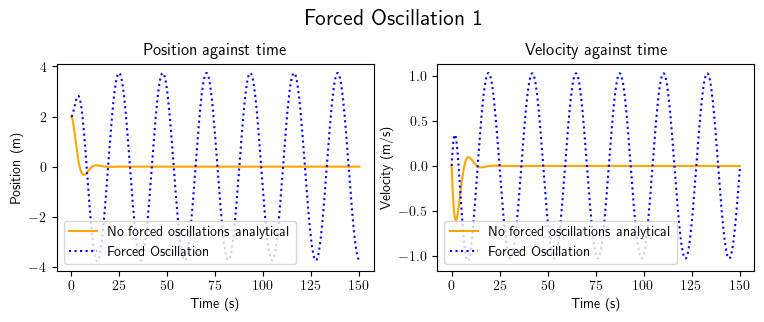

In [51]:
plt.rcParams["figure.figsize"] = (9,3)
fig,(ax1,ax2) = plt.subplots(1,2)
fig.suptitle(r"Forced Oscillation 1 ", fontsize=16)
fig.subplots_adjust(top=0.8)  # Adjust space for the title.

# Position plot.
ax1.plot(t_an_nforced1, x_an_nforced1, "orange", label="No forced oscillations analytical")
ax1.plot(t_forced1, x_forced1, "b:", label="Forced Oscillation")
ax1.set(xlabel="Time (s)")
ax1.set(ylabel="Position (m)")
ax1.set_title("Position against time", fontsize=12)
ax1.legend()


# Velocity plot.
ax2.plot(t_an_nforced1[:-1], v_an_nforced1[:-1], "orange", label="No forced oscillations analytical")
ax2.plot(t_forced1[:-1], v_forced1[:-1], "b:", label="Forced Oscillation")
# Use of [:-1] to remove the last element in the velocity arrays. As the verlet method returns one less term for velocity.
ax2.set(xlabel="Time (s)")
ax2.set(ylabel="Velocity (m/s)")
ax2.set_title("Velocity against time", fontsize=12)
ax2.legend()

Interestingly no matter the initial conditions the steady oscillations always occur for the same amplitude surrounding zero.

To demonstrate this we'll use initial conditions: 

1) $x_0 = 2$m & $v_0 = 0$m/s

2) $x_0 = 6$m & $v_0 = -3$m/s

3) $x_0 = 0$m & $v_0 = 0$m/s

In [52]:
# Extract the forced oscillation solutions.
x_forced2, v_forced2, t_forced2 = verlets_method_F_oscillations(0.001, 150, 6, -3, b_i, 3, omega_0 / 2)
x_forced3, v_forced3, t_forced3 = verlets_method_F_oscillations(0.001, 150, 0, 0, b_i, 3, omega_0 / 2)

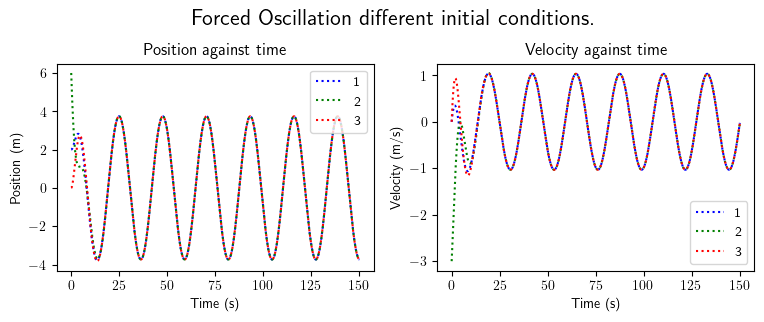

In [53]:
plt.rcParams["figure.figsize"] = (9,3)
fig,(ax1,ax2) = plt.subplots(1,2)
fig.suptitle(r"Forced Oscillation different initial conditions. ", fontsize=16)
fig.subplots_adjust(top=0.8)  # Adjust space for the title.

# Position plot.
ax1.plot(t_forced1, x_forced1, "b:", label="1")
ax1.plot(t_forced2, x_forced2, "g:", label="2")
ax1.plot(t_forced3, x_forced3, "r:", label="3")
ax1.set(xlabel="Time (s)")
ax1.set(ylabel="Position (m)")
ax1.set_title("Position against time", fontsize=12)
ax1.legend(loc="upper right")


# Velocity plot.
ax2.plot(t_forced1[:-1], v_forced1[:-1], "b:", label="1")
ax2.plot(t_forced2[:-1], v_forced2[:-1], "g:", label="2")
ax2.plot(t_forced3[:-1], v_forced3[:-1], "r:", label="3")
# Use of [:-1] to remove the last element in the velocity arrays. As the verlet method returns one less term for velocity.
ax2.set(xlabel="Time (s)")
ax2.set(ylabel="Velocity (m/s)")
ax2.set_title("Velocity against time", fontsize=12)
ax2.legend()

As you can see no matter the starting conditons all curves merge for the steady oscillations.

## 4. Stretch yourself

### 4.1 Effect of initialisation step on Verlet's method

After discussing my results for the order of Verlet's error with other coursemates, I was shocked to find they found it to be first order. After a long time of troubleshooting and trying  to debug my code I realised why. There is no issue with any of our code. The only difference was how we initialised (did the first step of) Verlet's method. My coursemates had used Standard Euler's and I had used Improved Euler's.

Let us show using the function verlet_method_standard, which has only changed the initialisation step, that by using the standard Euler's to initialise Verlet's it limits the methods error to first order. Possible reasons for why will be discussed. 

In [54]:
def verlet_err_standard(T, x_0, v_0, b):
    """
    T is the time we are integrating until, in seconds.
    x_0 is the initial condition for position.
    v_0 is the initial condition for velocity.
    b is the damping constant. Typically either b_i, b_crit, or b_iii

    h is the step size in seconds. It is varied, taking the values from h_values.

    This function finds the error between the verlet method and the analytical solution using the mean absolute error.
    It find this for all the h values specified

    It is using the verlets method which is initialised by standard Euler, to demonstrate the effect this has on accuracy.
    """
    
    h_values = np.array([0.0001, 0.0005, 0.001, 0.005, 0.01, 0.03, 0.05, 0.075, 0.1]) # Using h values used earlier in sections 2.3 - 2.5.

    # Creating arrays/matrix to put the errors in.
    x_ver_sigmas_h = np.zeros(len(h_values))
    v_ver_sigmas_h = np.zeros(len(h_values))

    # Iterating through the different h values.
    for i, h in enumerate(h_values):

        # Defing all the solutions for a certain h value.
        x_an, v_an, t = analytical_solutions(h, T, x_0, v_0, b)

        x_ver, v_ver, _ = verlets_method_standard(h, T, x_0, v_0, b)

        # Again finding the MAE of position and velocity. In this case only for verlets.
        x_sum_error = np.sum(np.abs(x_ver - x_an))
        x_N = len(x_ver)
        x_ver_sigmas_h[i] = x_sum_error / x_N

        v_sum_error = np.sum(np.abs(v_ver - v_an))
        v_N = len(v_ver)
        v_ver_sigmas_h[i] = v_sum_error / v_N

    # Plot of the errors against h value.
    plt.rcParams["figure.figsize"] = (9,10)
    fig, (ax1, ax2) = plt.subplots(2, 1)
    
    # Position plot.
    ax1.plot(h_values, x_ver_sigmas_h, linestyle='-', marker='o')
    ax1.set(xlabel=r"Time step $h$ s")
    ax1.set(ylabel="Error m")
    ax1.set_title(r"Error against time step $h$ (position)", fontsize=12)
    
    ax2.plot(h_values, v_ver_sigmas_h, linestyle='-', marker='o')
    ax2.set(xlabel=r"Time step $h$ s")
    ax2.set(ylabel="Error m/s")
    ax2.set_title("Error against time step $h$ (velocity)", fontsize=12)
    
    plt.show()

    return x_ver_sigmas_h, v_ver_sigmas_h

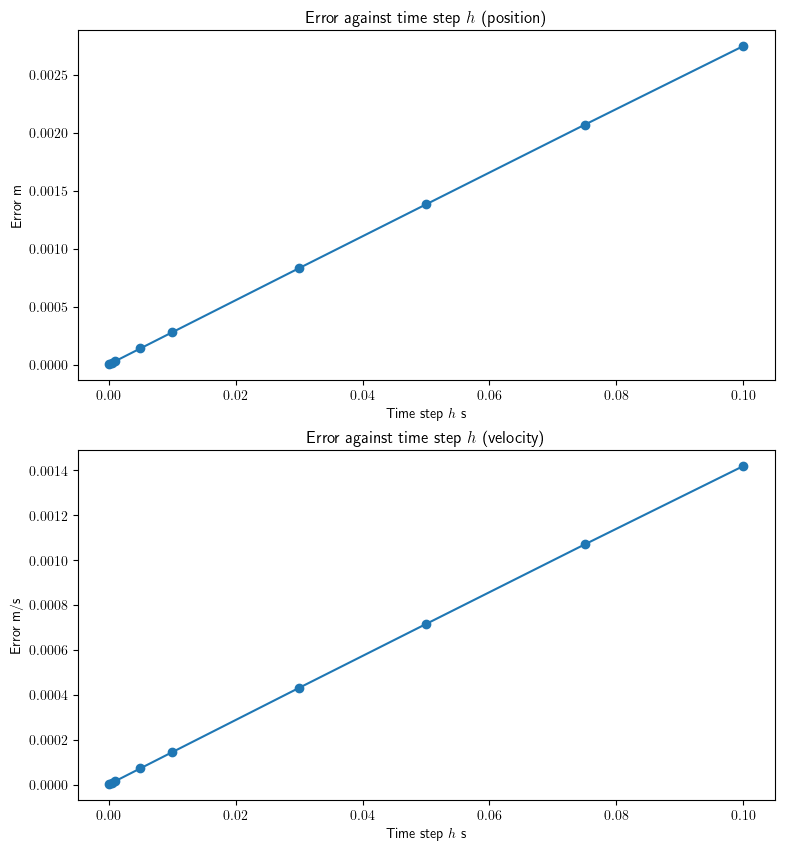

In [55]:
# Extracting the data for Verlet's method initialised with the Standard Euler's method.
x_ver_stand_sigmas_h_b_i, v_ver_stand_sigmas_h_b_i = verlet_err_standard(50, 2, 0, b_i)

From these plots we can see the order of error is clearly first order as it is a straight line for both position & velocity. However let us check by finding the gradient of the log graphs.

In [56]:
h_values = np.array([0.0001, 0.0005, 0.001, 0.005, 0.01, 0.03, 0.05, 0.075, 0.1])

# Compute the logarithms of the values.
log_h_values = np.log(h_values)

# Position.
log_x_ver_stand_sigmas_h_b_i = np.log(x_ver_stand_sigmas_h_b_i)

# Velocity.
log_v_ver_stand_sigmas_h_b_i = np.log(v_ver_stand_sigmas_h_b_i)

In [57]:
# Perform linear fits to find gradients for position.
slope_x_ver_stand, _ = np.polyfit(log_h_values, log_x_ver_stand_sigmas_h_b_i, 1)

# Perform linear fits to find gradients for velocity.
slope_v_ver_stand, _ = np.polyfit(log_h_values, log_v_ver_stand_sigmas_h_b_i, 1)

# Print the gradients/orders
print("Gradients/orders for Position Errors:")
print(f"Verlet's Method (with standard Euler's initialisation): {slope_x_ver_stand:.4f}")

print("\nGradients/orders for Velocity Errors:")
print(f"Verlet's Method (with standard Euler's initialisation): {slope_v_ver_stand:.4f}")

Gradients/orders for Position Errors:
Verlet's Method (with standard Euler's initialisation): 0.9987

Gradients/orders for Velocity Errors:
Verlet's Method (with standard Euler's initialisation): 0.9981


These gradients confirm what we thought.

It is quite interesting that the choice of initialisation step effects the order of error that Verlet's method possesses. I beleive this can be explained/rationalised by the local errors associated to the position of the standard & improved Euler method.

The standard Euler's position has a local error of $O(h^2)$ which when multiplied by $T/h$ we see the error associated to position will be of first order.

The improved Euler's position has a local error of $O(h^3)$ which when multiplied by $T/h$ we see the error associated to position will be of second order.

Originally when thinking of Verlet's method (initialised by improved Euler's) we explained the order of $h^2$ by saying "We can see this is between the local errors $O(h^4)$ and $O(h^2)$ when divided by $h$ (multiplied by $T/h$) to find the global error".

I think that the standard Euler's local error of $O(h^2)$ shifts the global error more towards the first order, restricting it. However the improved Euler's local error of $O(h^3)$ contributes to higher order global error. Still restricting the local error for Verlet's postion of $O(h^4)$ but being higher than the local error for velocity $O(h^2)$. I think this now makes even more sense why the global error is between the local errors when they aremultipled by $T/h$.

I am interested in anymore clarity that can be provided on this topic.

### 4.2 Investigation of resonance

Let us investiagte resonance of forced oscillations, which should occur around $\Omega = \omega_0$.

Let us plot the forced oscillations of $b = b_1$ for $\Omega = \frac{\omega_0}{2}$ & $\Omega = \omega_0$.

In [58]:
# Extract the forced oscillation solutions. Dropped time step in order to lower runtime
x_res_b_1, v_res_b_1, t_res_b_1 = verlets_method_F_oscillations(0.01, 400, 2, 0, b_1, 3, omega_0)
x_forced_b_1, v_forced_b_1, t_forced_b_1 = verlets_method_F_oscillations(0.01, 400, 2, 0, b_1, 3, omega_0 / 2)

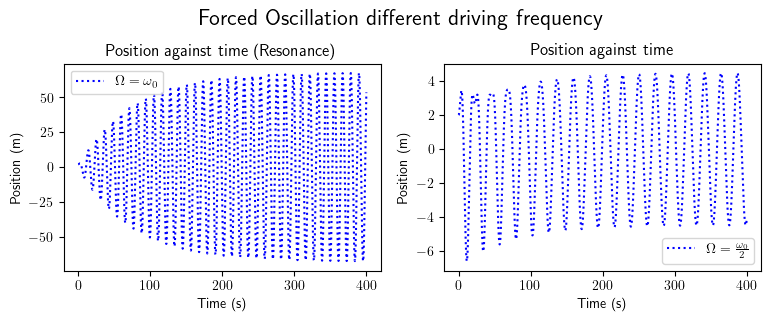

In [59]:
plt.rcParams["figure.figsize"] = (9,3)
fig,(ax1,ax2) = plt.subplots(1,2)
fig.suptitle(r"Forced Oscillation different driving frequency", fontsize=16)
fig.subplots_adjust(top=0.8)  # Adjust space for the title.

# Resonance plot.
ax1.plot(t_res_b_1, x_res_b_1, "b:", label=r"$\Omega = \omega_0$")
ax1.set(xlabel="Time (s)")
ax1.set(ylabel="Position (m)")
ax1.set_title("Position against time (Resonance)", fontsize=12)
ax1.legend(loc="upper left")


# Half natural freq plot.
ax2.plot(t_forced_b_1, x_forced_b_1, "b:", label=r"$\Omega = \frac{\omega_0}{2}$")
ax2.set(xlabel="Time (s)")
ax2.set(ylabel="Position (m)")
ax2.set_title("Position against time", fontsize=12)
ax2.legend()

This is what we'd expect to see physically. For the plot on the left we see resonance near the natural frequency. On the right we see a transient period after which steady oscillation emerge.

Let us try this for forced oscillations of $b = b_i$ for $\Omega = \frac{\omega_0}{2}$ & $\Omega = \omega_0$.

In [60]:
# Extract the forced oscillation solutions. Dropped time step in order to lower runtime
x_res_b_i, v_res_b_i, t_res_b_i = verlets_method_F_oscillations(0.01, 150, 2, 0, b_i, 3, omega_0)
x_forced_b_i, v_forced_b_i, t_forced_b_i = verlets_method_F_oscillations(0.01, 150, 2, 0, b_i, 3, omega_0 / 2)

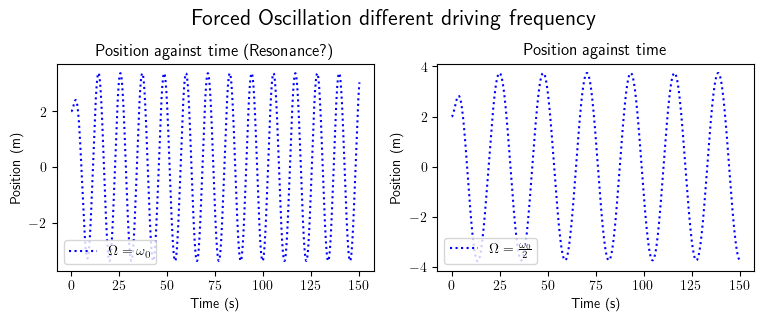

In [61]:
plt.rcParams["figure.figsize"] = (9,3)
fig,(ax1,ax2) = plt.subplots(1,2)
fig.suptitle(r"Forced Oscillation different driving frequency", fontsize=16)
fig.subplots_adjust(top=0.8)  # Adjust space for the title.

# Resonance plot.
ax1.plot(t_res_b_i, x_res_b_i, "b:", label=r"$\Omega = \omega_0$")
ax1.set(xlabel="Time (s)")
ax1.set(ylabel="Position (m)")
ax1.set_title("Position against time (Resonance?)", fontsize=12)
ax1.legend(loc="lower left")


# Half natural freq plot.
ax2.plot(t_forced_b_i, x_forced_b_i, "b:", label=r"$\Omega = \frac{\omega_0}{2}$")
ax2.set(xlabel="Time (s)")
ax2.set(ylabel="Position (m)")
ax2.set_title("Position against time", fontsize=12)
ax2.legend(loc="lower left")

Here we don't see that resonance occurs around $\Omega = \omega_0$ for $b = b_i$, as the amplitude is greater at $\Omega = \frac{\omega_0}{2}$.

After discussing this with the demonstrator, it is clear why this occurs and it is not the fault of the numerical method. This is actually physically correct.

Amplitude for long term forced oscillations can be defined by the equation: $A = \frac{\frac{F_0}{m}}{\sqrt{(\omega_0^2 - \omega^2)^2 + \omega^2 \gamma^2}}$.

When $b$ and therefore $\gamma$ is small ($b=b_1$) the second term in the denominator can be neglected. This is the case when resonance occurs around $\Omega = \omega_0$.

When $b$ and therefore $\gamma$ is large ($b=b_i$) the second term in the denominator can't be neglected. Therefore resonance no longer occurs around $\Omega = \omega_0$.

Let us plot how amplitude $A$ changes with $\Omega$.

In [62]:
def find_amplitude(x, t, t_s):
    """
    x the position array of a forced oscillation.
    t the time array of a forced oscillation.
    t_s the time at which the forced oscillation is now definetely steady state.
    
    Finds the amplitude of the steady-state oscillations.
    """
    
    t_s_ind = np.argmin(np.abs(t - t_s)) # Determine index corresponding to t_s.
    steady_state_x = x[t_s:]  # Consider only part of it to ignore transients. Decided by t_s.
    return (max(steady_state_x) - min(steady_state_x)) / 2  # Pk-to-pk / 2

In [63]:
def plot_amplitude_vs_freq(h, T, x_0, v_0, b, F_0, t_s, freq_range):
    """
    h is the step size in seconds.
    T is the time we are integrating until, in seconds.
    x_0 is the initial condition for position.
    v_0 is the initial condition for velocity.
    b is the damping constant. It is b_1 unless stated otherwise.
    F_0 is the amplitude of the force applied in N. This holds the direction at which it is initially applied.
    freq_range is the possible driving frequencies that will be plotted.
    t_s is the time at which the oscillations are definetely steady state.

    This function plots amplitude as a function of driving frequency. It uses the functions:
    verlets_method_F_oscillations() & find_amplitude() to do so.
    """
    
    amplitudes = []
    for freq in freq_range:
        x, _, t = verlets_method_F_oscillations(h, T, x_0, v_0, b, F_0, freq)
        amplitudes.append(find_amplitude(x, t, t_s))
    
    plt.plot(freq_range, amplitudes)
    plt.axvline(x=omega_0, color='r', linestyle='--', label=r"$\omega_0$")
    plt.axvline(x=omega_0/2, color='orange', linestyle='--', label=r"$\frac{\omega_0}{2}$")
    plt.xlabel(r"Driving Frequency")
    plt.ylabel("Amplitude m")
    plt.title("Amplitude against Driving Frequency")
    plt.legend()
    plt.show()

In [64]:
# Define freq_range
freq_range1 = np.arange(0.1, 1, 0.01)

Let us plot for our first instance, forced oscillations of $b = b_1$.

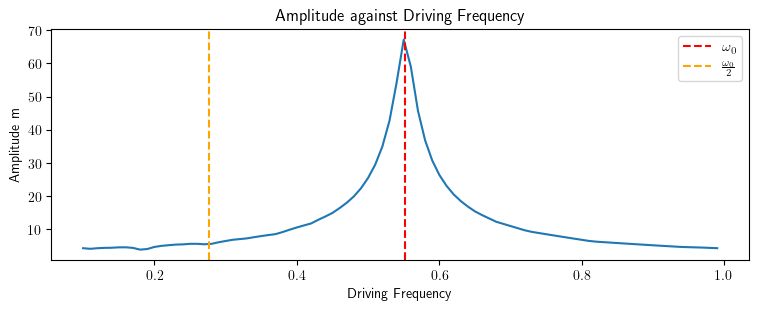

In [65]:
# Plotting for b = b_1.
plot_amplitude_vs_freq(0.01, 400, 2, 0, b_1, 3, 300, freq_range1)

As we can see the peak amplitude (resonance) occurs very close to the natural frequency for the very light damping case of $b = b_1$

Let us plot for our second instance, forced oscillations of $b = b_1$.

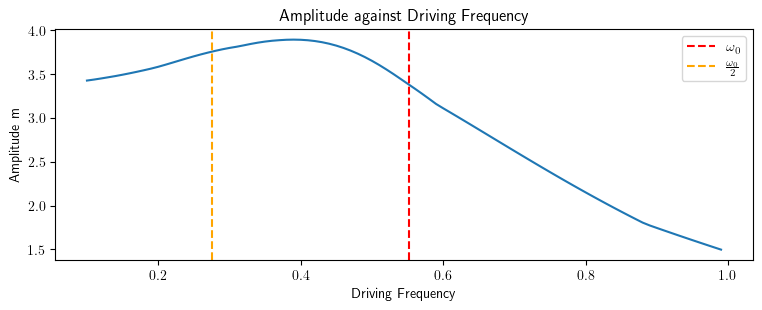

In [66]:
# Plotting for b = b_i.
plot_amplitude_vs_freq(0.01, 400, 2, 0, b_i, 3, 300, freq_range1)

This plot also explains why the amplitude is higher for $\Omega = \frac{\omega_0}{2}$ than for $\Omega = \omega_0$ at damping $b = b_i$. With the peak around $\Omega \approx 0.4$.

## 5. Conclusion

In this project, we have demonstrated that numerical methods are valuable tools for predicting the physical behavior of a system. By comparing these methods against known analytical solutions, we assessed their accuracy and reliability. We observed that while Euler’s and improved Euler’s failed to conserve energy, Verlet’s and Euler-Cromer successfully preserved it.

To evaluate the accuracy of these methods, we analyzed the mean absolute error (MAE) as a function of the time step $h$.
We found that reducing $h$ generally decreased the error, but beyond a certain threshold rounding errors introduced by the computer became significant increasing the error.

Verlet’s method proved to be the most accurate, with the choice of initialisation affecting the order of error. Using this method, we simulated systems with external forces and obtained results consistent with physical expectations. Notable observations included:

- A forced push changing the oscillation amplitude.
- A transient phase transitioning into steady forced oscillations.
- Resonance occurring near $\Omega = \omega_0$ in the very light damping regime.

These findings highlight that numerical methods can be powerful tools for modeling systems without analytical solutions. However, careful consideration of the time step and physical parameters is crucial, as they directly impact the accuracy of predictions.

## 6. Appendix: Investigation of zero external force $F(t) = 0$

As mentioned in section 1 this appendix contains the process I went through checking that the methods looked appropiate. It is not essential but if you wish to look.

$m\ddot{x} + b\dot{x} + kx = 0$

The aim of this section is to calculate solutions of  $x(t)$ for the four proposed numerical methods: Euler, improved Euler, Verlet & Euler-Cromer.

When the external force is equal to zero it is easy to find a solution analytically. This can allow us to check the validity of our numerical methods.

This is useful to know for when $F(t) \neq 0$, as it is much harder to find a solution analytically. We use our previous 'factcheck' to understand to what degree we can trust these numerical methods.

### 6.1 Analytical solutions - zero external force

Finding the analytical solutions.

$m\ddot{x} + b\dot{x} + kx = 0$

$\ddot{x} + \frac{b}{m}\dot{x} + \frac{k}{m}x = 0$

$\ddot{x} + \gamma\dot{x} + \omega_0^2x = 0$, where $\gamma = \frac{b}{m}$ and $\omega_0^2 = \frac{k}{m}$.

Starting again with the general solution to light damping, $x(t) = A \exp\left(-\frac{\gamma}{2} t\right) \cos(\omega t + \Phi); \quad \omega = \sqrt{\omega_0^2 - \frac{\gamma^2}{4}}.$
Where $A$ is an amplitude constant and $\Phi$ is a phase.

$x(t) = A \exp\left(-\frac{\gamma}{2} t\right) \cos(\omega t + \Phi)$

$v(t) = \frac{d}{dt}x(t)$, therefore $v(t) = - A \exp\left(-\frac{\gamma}{2} t\right) \left( \frac{\gamma}{2} \cos(\omega t + \Phi) + \omega \sin(\omega t + \Phi) \right)$

We can find that the initial conditions provided relate to $A$ & $\Phi$ as follows:

$x_0 = Acos(\Phi)$

$v_0 = -A \left( \frac{\gamma}{2} \cos(\Phi) + \omega \sin(\Phi) \right)$

From above we can find $A$ & $\Phi$ in terms of the initial conditions $x_0$ & $v_0$.

$A = \sqrt{x_0^2 + \frac{(\frac{x_0 \gamma}{2} + v_0)^2}{\omega^2}}$

$\Phi = \arctan(- \frac{v_0 + \frac{x_0 \gamma}{2}}{x_0 \omega})$



We also must consider heavy & critical damping. Where $b_{cr}$ is the critical damping constant.

If $\frac{\gamma^2}{4} < \omega_0^2$, $b < b_{cr}$, this is light damping.

If $\frac{\gamma^2}{4} > \omega_0^2$, $b > b_{cr}$, this is heavy damping.

If $\frac{\gamma^2}{4} = \omega_0^2$, $b = b_{cr}$ this is critical damping.

The solution for heavy damping is $x(t) = \exp\left( -\frac{\gamma}{2} t \right) \left[ C \exp(\alpha t) + D \exp(-\alpha t) \right]$, where $\alpha = \sqrt{\frac{\gamma^2}{4} - \omega_0^2}$.

$v(t) = e^{-\frac{\gamma}{2} t} \left[ C (\alpha - \frac{\gamma}{2}) e^{\alpha t} - D (\alpha + \frac{\gamma}{2}) e^{-\alpha t} \right]$

$C$ & $D$ are related to the initial conditions by the following:

$C = \frac{x_0 \left(\alpha + \frac{\gamma}{2} \right) + v_0}{2\alpha}$

$D = \frac{x_0 \left(\alpha - \frac{\gamma}{2} \right) - v_0}{2\alpha}$

The solution to critical damping is:

$x(t) = E \exp\left(-\frac{\gamma}{2} t\right) + F t \exp\left(-\frac{\gamma}{2} t\right)$

$v(t) = \exp(-\frac{\gamma}{2} t)(-\frac{\gamma}{2} E + F -\frac{\gamma}{2}Ft )  $

Where $E$ & $F$ are related to the initial conditions by:

$E = x_0$

$F = \frac{\gamma}{2}x_0 + v_0$ 

Now defining the analytical solution function.

In [67]:
def analytical_solutions(h, T, x_0, v_0, b=b_1):
    """
    h is the step size in seconds.
    T is the time we are integrating until, in seconds.
    x_0 is the initial condition for position.
    v_0 is the initial condition for velocity.
    b is the damping constant. It is b_1 unless stated otherwise.

    This function uses the equations in the above markdown to find the analytical solutions.
    Using if statements to decide what kind of damping it is.

    It returns the arrays of position, velocity & time.
    """
    
    no_steps = int(T/h) # Determine how many whole number steps are within T. Each step is one i.
    t = np.arange(0, (no_steps * h), h) # Define time intervals for each step. Useful for when we plot.

    gamma = b / m
    omega_0_sqrd = k / m 
    # omega = np.sqrt( omega_0_sqrd - (gamma**2 / 4)) Is imaginary for heavy and critical. Just moved it inside the if for light damping.

    if b < b_crit:

        #print("light")

        omega = np.sqrt( omega_0_sqrd - (gamma**2 / 4))
        
        A = np.sqrt(x_0**2 + ( (x_0 * gamma /2) + v_0 )**2 / omega**2)

        Phi = np.arctan2(-1 * ( v_0 + (x_0 * gamma /2) ), (x_0 * omega)) # arctan2 handles when the argument is around 0 better.

        x = A * np.exp(- t * gamma / 2) * np.cos(omega * t + Phi) # Calculating the analytical x solutions.

        v = - A * np.exp(- t * gamma / 2) * ( (gamma / 2) * np.cos(omega * t + Phi) + omega * np.sin(omega * t + Phi) ) # Calculating the analytical v solutions. 
    
    elif round(b, 4) == round(b_crit, 4): # The round is used otherwise b must match the critical b to a very high precision
    
        #print("critical")
    
        E = x_0
    
        F = (gamma / 2) * x_0 + v_0
    
        x = E * np.exp(- gamma * t / 2) + F * t * np.exp(- gamma * t / 2)
    
        v = np.exp(- gamma * t / 2) * ((- gamma / 2 ) * E + F + (- gamma / 2) * F * t)
    
    elif b > b_crit:

        #print("heavy")

        alpha = np.sqrt((gamma**2 / 4) - omega_0_sqrd)

        C = (x_0 * (alpha + gamma / 2) + v_0) / (2 * alpha)

        D = (x_0 * (alpha - gamma / 2) - v_0) / (2 * alpha)

        x = np.exp(- gamma * t / 2) * (C * np.exp(alpha * t) + D * np.exp(- alpha * t))

        v = np.exp(- gamma * t / 2) * (C * (alpha - gamma / 2) * np.exp(alpha * t) - D * (alpha + gamma / 2) * np.exp(- alpha * t))

        
    return x, v, t

Let us check that this works for different initial conditions.

Text(0.5, 1.0, 'Velocity against time')

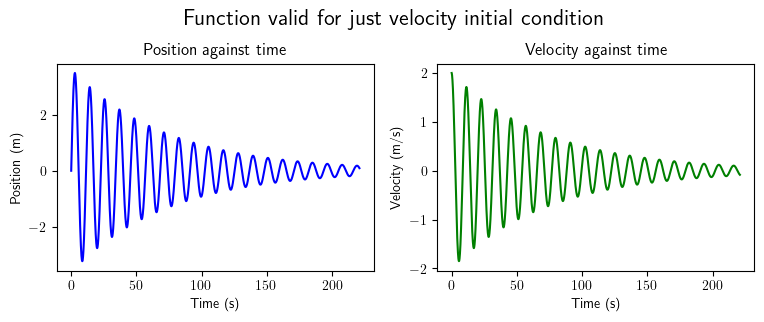

In [68]:
x_an_example2, v_an_example2, t_example2 = analytical_solutions(0.01, 221, 0, 2)

plt.rcParams["figure.figsize"] = (9,3)
fig,(ax1,ax2) = plt.subplots(1,2)
fig.suptitle("Function valid for just velocity initial condition", fontsize=16)
fig.subplots_adjust(top=0.8)  # Adjust space for the title.

# Position plot.
ax1.plot(t_example2, x_an_example2, "b")
ax1.set(xlabel="Time (s)")
ax1.set(ylabel="Position (m)")
ax1.set_title("Position against time", fontsize=12)

# Velocity plot.
ax2.plot(t_example2, v_an_example2, "g")
ax2.set(xlabel="Time (s)")
ax2.set(ylabel="Velocity (m/s)")
ax2.set_title("Velocity against time", fontsize=12)

Check for $x_0 = 2$m & $v_0 = 0$m/s

Text(0.5, 1.0, 'Velocity against time')

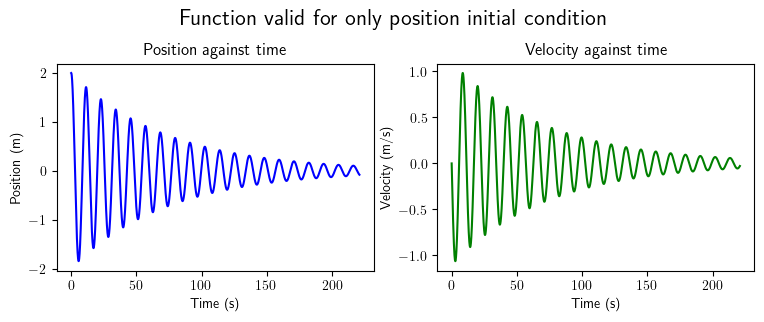

In [69]:
x_an_example3, v_an_example3, t_example3 = analytical_solutions(0.01, 221, 2, 0)

plt.rcParams["figure.figsize"] = (9,3)
fig,(ax1,ax2) = plt.subplots(1,2)
fig.suptitle("Function valid for only position initial condition", fontsize=16)
fig.subplots_adjust(top=0.8)  # Adjust space for the title.

# Position plot.
ax1.plot(t_example3, x_an_example3, "b")
ax1.set(xlabel="Time (s)")
ax1.set(ylabel="Position (m)")
ax1.set_title("Position against time", fontsize=12)

# Velocity plot.
ax2.plot(t_example3, v_an_example3, "g")
ax2.set(xlabel="Time (s)")
ax2.set(ylabel="Velocity (m/s)")
ax2.set_title("Velocity against time", fontsize=12)

Let us try for when both postion and velocity have non-zero initial conditions.

$x_0 = 2$m & $v_0 = -1$m/s

Text(0.5, 1.0, 'Velocity against time')

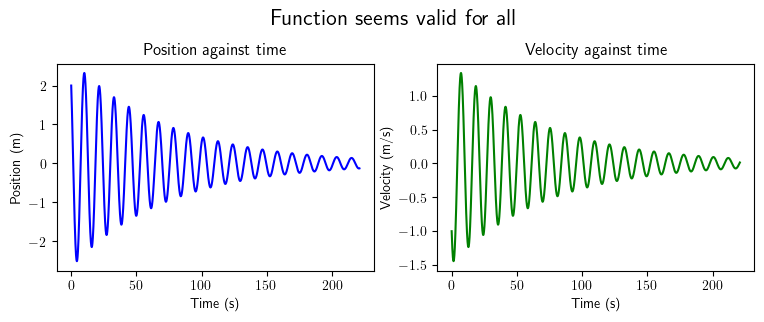

In [70]:
x_an_example4, v_an_example4, t_example4 = analytical_solutions(0.01, 221, 2, -1)

plt.rcParams["figure.figsize"] = (9,3)
fig,(ax1,ax2) = plt.subplots(1,2)
fig.suptitle("Function seems valid for all", fontsize=16)
fig.subplots_adjust(top=0.8)  # Adjust space for the title.

# Position plot.
ax1.plot(t_example4, x_an_example4, "b")
ax1.set(xlabel="Time (s)")
ax1.set(ylabel="Position (m)")
ax1.set_title("Position against time", fontsize=12)

# Velocity plot.
ax2.plot(t_example4, v_an_example4, "g")
ax2.set(xlabel="Time (s)")
ax2.set(ylabel="Velocity (m/s)")
ax2.set_title("Velocity against time", fontsize=12)

This looks valid. We would expect the position to be higher for it's first oscillation (first time back round).

Let us have a look at heavy damping.

Text(0.5, 1.0, 'Velocity against time')

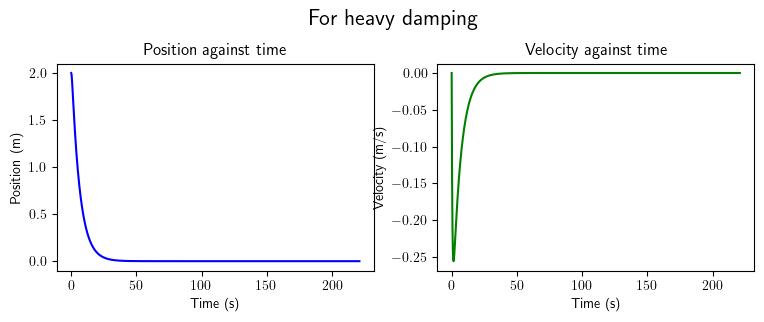

In [71]:
x_an_example5, v_an_example5, t_example5 = analytical_solutions(0.01, 221, 2, 0, 6)

plt.rcParams["figure.figsize"] = (9,3)
fig,(ax1,ax2) = plt.subplots(1,2)
fig.suptitle("For heavy damping", fontsize=16)
fig.subplots_adjust(top=0.8)  # Adjust space for the title.

# Position plot.
ax1.plot(t_example5, x_an_example5, "b")
ax1.set(xlabel="Time (s)")
ax1.set(ylabel="Position (m)")
ax1.set_title("Position against time", fontsize=12)

# Velocity plot.
ax2.plot(t_example5, v_an_example5, "g")
ax2.set(xlabel="Time (s)")
ax2.set(ylabel="Velocity (m/s)")
ax2.set_title("Velocity against time", fontsize=12)

Let us look at critical damping.

Text(0.5, 1.0, 'Velocity against time')

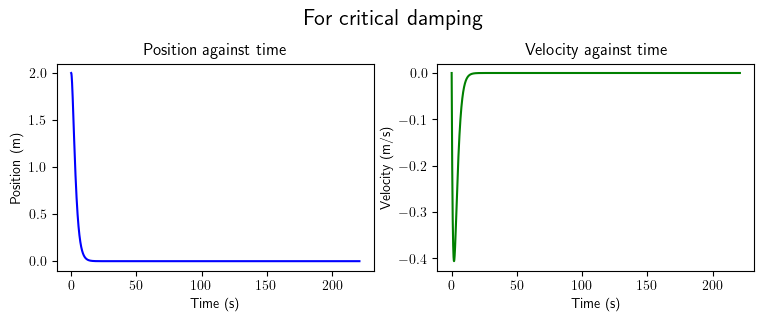

In [72]:
x_an_example6, v_an_example6, t_example6 = analytical_solutions(0.01, 221, 2, 0, 3.2242)

plt.rcParams["figure.figsize"] = (9,3)
fig,(ax1,ax2) = plt.subplots(1,2)
fig.suptitle("For critical damping", fontsize=16)
fig.subplots_adjust(top=0.8)  # Adjust space for the title.

# Position plot.
ax1.plot(t_example6, x_an_example6, "b")
ax1.set(xlabel="Time (s)")
ax1.set(ylabel="Position (m)")
ax1.set_title("Position against time", fontsize=12)

# Velocity plot.
ax2.plot(t_example6, v_an_example6, "g")
ax2.set(xlabel="Time (s)")
ax2.set(ylabel="Velocity (m/s)")
ax2.set_title("Velocity against time", fontsize=12)

The below methods are tested with light damping.

### 6.2 Euler's method - zero external force

Eulers method approximates the integral $y$ as a sum of $\delta y = \frac{dy}{dx}\delta t = y = \frac{dy}{dx} h $, where $\delta t = h $ is the step size.

We can see:

$x(t+h) = x(t) + hv(t)$

$v(t+h) = v(t) + ha(t)$

$x_{i+1} = x_i + hv_i$ (1.3)

$v_{i+1} = v_i + ha_i$ (1.4)

where $a_i = -\frac{k}{m}x_i - \frac{b}{m}v_i$ (1.5)

This is Eulers method.

In [73]:
def eulers_method(h, T, x_0, v_0, b=b_1):
    """
    h is the step size in seconds.
    T is the time we are integrating until, in seconds.
    x_0 is the initial condition for position.
    v_0 is the initial condition for velocity.
    b is the damping constant. It is b_1 unless stated otherwise.

    This function uses the equations in the above markdown to carry out euler's numerical method.

    It returns the arrays of position, velocity & time.
    """

    no_steps = int(T/h) # Determine how many whole number steps are within T. Each step is one i.
    
    x = np.zeros(no_steps) # Empty array for position.
    v = np.zeros(no_steps) # Empty array for velocity.

    # Use the initial conditions from the function arguments.
    x[0] = x_0
    v[0] = v_0

    for i in range(no_steps - 1):

        a = -(k / m) * x[i] - (b / m) * v[i] # Acceleration at step i, using eqn 1.5.

        x[i+1] = x[i] + h * v[i] # x at later step i+1, using eqn 1.3.
        v[i+1] = v[i] + h * a # v at later step i+1, using eqn 1.4.

    t = np.arange(0, (no_steps * h), h) # Define time intervals for each step. Useful for when we plot.
    
    return x, v, t

Use the above function for:

step size h = 0.01 s

total time T = 221 s

initial position x_0 = 2 m

initial velocity v_0 = 0 m/s

Let us plot and see if we get what we'd expect. We would expect a sinusoidal decay for both.

Text(0.5, 1.0, 'Velocity against time')

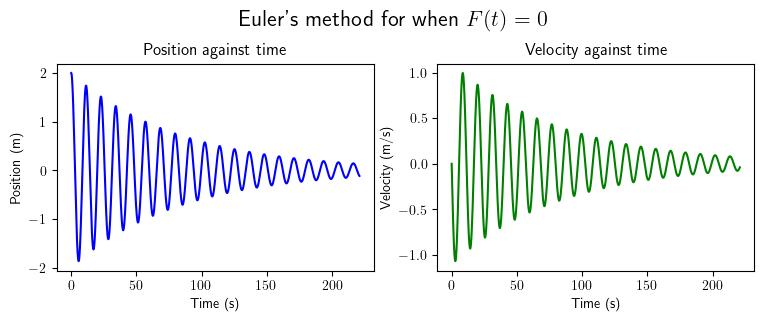

In [74]:
x_euler, v_euler, t = eulers_method(0.01, 221, 2, 0)

plt.rcParams["figure.figsize"] = (9,3)
fig,(ax1,ax2) = plt.subplots(1,2)
fig.suptitle(r"Euler's method for when $F(t) = 0$", fontsize=16)
fig.subplots_adjust(top=0.8)  # Adjust space for the title.

# Position plot.
ax1.plot(t, x_euler, "b")
ax1.set(xlabel="Time (s)")
ax1.set(ylabel="Position (m)")
ax1.set_title("Position against time", fontsize=12)

# Velocity plot.
ax2.plot(t, v_euler, "g")
ax2.set(xlabel="Time (s)")
ax2.set(ylabel="Velocity (m/s)")
ax2.set_title("Velocity against time", fontsize=12)

These look appropiate, lets compare them to analytical solutions.

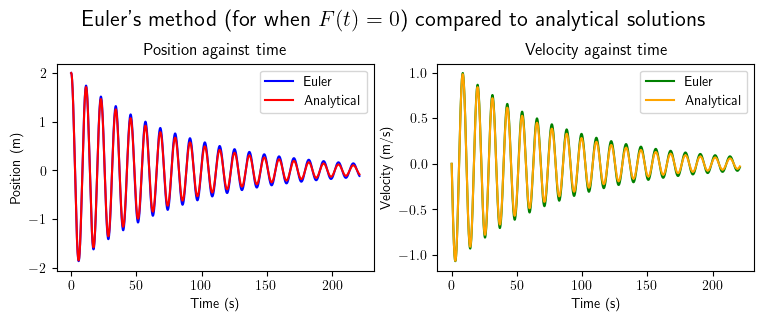

In [75]:
x_an, v_an, t_an = analytical_solutions(0.01, 221, 2, 0) # Returns analytical solutions for x & v. If done correctly t_an should be the same as t.

"""if np.all(t_an) == np.all(t): # Checking the above is true.
    print("True")"""

# Plot the solutions found from Euler's method with the analytical solutions.

plt.rcParams["figure.figsize"] = (9,3)
fig,(ax1,ax2) = plt.subplots(1,2)
fig.suptitle(r"Euler's method (for when $F(t) = 0$) compared to analytical solutions", fontsize=16)
fig.subplots_adjust(top=0.8)  # Adjust space for the title.

# Position plot.
ax1.plot(t, x_euler, "b", label="Euler")
ax1.plot(t, x_an, "r", label="Analytical")
ax1.set(xlabel="Time (s)")
ax1.set(ylabel="Position (m)")
ax1.set_title("Position against time", fontsize=12)
ax1.legend()

# Velocity plot.
ax2.plot(t, v_euler, "g", label="Euler")
ax2.plot(t, v_an, "orange", label="Analytical")
ax2.set(xlabel="Time (s)")
ax2.set(ylabel="Velocity (m/s)")
ax2.set_title("Velocity against time", fontsize=12)
ax2.legend()

From above we can see that the Euler method has done a good job. For both postion & velocity the numerical solutions are in phase with the analytical solutions.

However it is clear that the analytical solution's amplitudes drop initially and are then lower throughout.

Let's check euler's method is appropiate for different initial conditions. $x_0 = -1.5$m $v_0 = 3$m/s

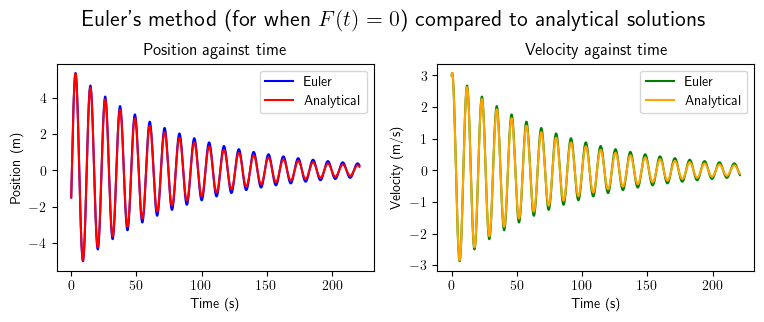

In [76]:
x_euler1, v_euler1, t = eulers_method(0.01, 221, -1.5, 3)

x_an_euler1, v_an_euler1, t_an_euler1 = analytical_solutions(0.01, 221, -1.5, 3) 

# Plot the solutions found from Euler's method with the analytical solutions.

plt.rcParams["figure.figsize"] = (9,3)
fig,(ax1,ax2) = plt.subplots(1,2)
fig.suptitle(r"Euler's method (for when $F(t) = 0$) compared to analytical solutions", fontsize=16)
fig.subplots_adjust(top=0.8)  # Adjust space for the title.

# Position plot.
ax1.plot(t, x_euler1, "b", label="Euler")
ax1.plot(t, x_an_euler1, "r", label="Analytical")
ax1.set(xlabel="Time (s)")
ax1.set(ylabel="Position (m)")
ax1.set_title("Position against time", fontsize=12)
ax1.legend()

# Velocity plot.
ax2.plot(t, v_euler1, "g", label="Euler")
ax2.plot(t, v_an_euler1, "orange", label="Analytical")
ax2.set(xlabel="Time (s)")
ax2.set(ylabel="Velocity (m/s)")
ax2.set_title("Velocity against time", fontsize=12)
ax2.legend()

Again is similar to the analytical solution which reinforces our beleif in the euler method.

### 6.3 Improved Euler's method - zero external force

We can improve upon Euler's method by using an extra term in the taylor series expansion for $x$.

$x(t + h) = x(t) + h\dot{x}(t) + \frac{1}{2}h^2\ddot{x}(t) + O(h^3)$, where the error is now of a higher order than the standard euler method.

$x_{i+1} = x_i + hv_i + \frac{h^2}{2}a_i$

Velocity step stays the same, $v_{i+1} = v_i + ha_i$, so does the order of error which will restrict the global error.

As before, $a_i = -\frac{k}{m}x_i - \frac{b}{m}v_i$

In [77]:
def eulers_improved_method(h, T, x_0, v_0, b=b_1):
    """
    h is the step size in seconds.
    T is the time we are integrating until, in seconds.
    x_0 is the initial condition for position.
    v_0 is the initial condition for velocity.
    b is the damping constant. It is b_1 unless stated otherwise.

    This function uses the equations in the above markdown to carry out euler's improved numerical method.

    It returns the arrays of position, velocity & time.
    """

    no_steps = int(T/h) # Determine how many whole number steps are within T. Each step is one i.
    
    x = np.zeros(no_steps) # Empty array for position.
    v = np.zeros(no_steps) # Empty array for velocity.

    # Use the initial conditions from the function arguments.
    x[0] = x_0
    v[0] = v_0

    for i in range(no_steps - 1):

        a = -(k / m) * x[i] - (b / m) * v[i] # Acceleration at step i, using eqn 1.5.

        x[i+1] = x[i] + h * v[i] + (h**2 / 2) * a # x at later step i+1, using eqn 1.6.
        v[i+1] = v[i] + h * a # v at later step i+1, using eqn 1.4.

    t = np.arange(0, (no_steps * h), h) # Define time intervals for each step. Useful for when we plot.
    
    return x, v, t

Let us plot and compare to the analytical solutions.

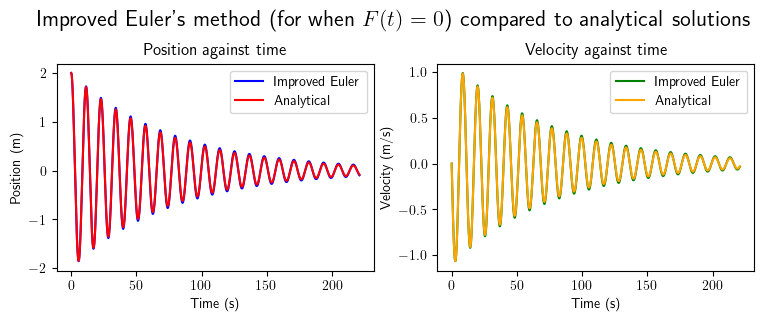

In [78]:
x_euler_imp, v_euler_imp, t = eulers_improved_method(0.01, 221, 2, 0) # Extracting the improved Euler method solutions.

# Plot the solutions found from the Improved Euler's method with the analytical solutions.

plt.rcParams["figure.figsize"] = (9,3)
fig,(ax1,ax2) = plt.subplots(1,2)
fig.suptitle(r"Improved Euler's method (for when $F(t) = 0$) compared to analytical solutions", fontsize=16)
fig.subplots_adjust(top=0.8)  # Adjust space for the title.

# Position plot.
ax1.plot(t, x_euler_imp, "b", label="Improved Euler")
ax1.plot(t, x_an, "r", label="Analytical")
ax1.set(xlabel="Time (s)")
ax1.set(ylabel="Position (m)")
ax1.set_title("Position against time", fontsize=12)
ax1.legend()

# Velocity plot.
ax2.plot(t, v_euler_imp, "g", label="Improved Euler")
ax2.plot(t, v_an, "orange", label="Analytical")
ax2.set(xlabel="Time (s)")
ax2.set(ylabel="Velocity (m/s)")
ax2.set_title("Velocity against time", fontsize=12)
ax2.legend()

This is closer to the Analytical method than the standard Euler's method. However still we see the amplitude is slightly larger than the analytical solution. 

Let's check the improved euler's method is appropiate for different initial conditions. $x_0 = 9$m $v_0 = -0.1$m/s

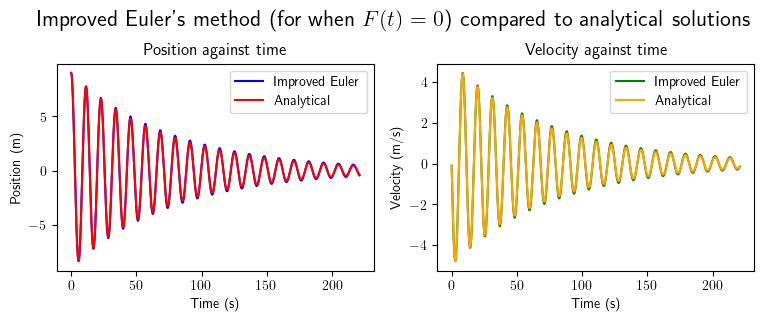

In [79]:
x_euler_imp1, v_euler_imp1, t = eulers_improved_method(0.01, 221, 9, -0.1) # Extracting the improved Euler method solutions.

x_an_imp1, v_an_imp1, t_an_imp1 = analytical_solutions(0.01, 221, 9, -0.1)
# Plot the solutions found from the Improved Euler's method with the analytical solutions.

plt.rcParams["figure.figsize"] = (9,3)
fig,(ax1,ax2) = plt.subplots(1,2)
fig.suptitle(r"Improved Euler's method (for when $F(t) = 0$) compared to analytical solutions", fontsize=16)
fig.subplots_adjust(top=0.8)  # Adjust space for the title.

# Position plot.
ax1.plot(t, x_euler_imp1, "b", label="Improved Euler")
ax1.plot(t, x_an_imp1, "r", label="Analytical")
ax1.set(xlabel="Time (s)")
ax1.set(ylabel="Position (m)")
ax1.set_title("Position against time", fontsize=12)
ax1.legend()

# Velocity plot.
ax2.plot(t, v_euler_imp1, "g", label="Improved Euler")
ax2.plot(t, v_an_imp1, "orange", label="Analytical")
ax2.set(xlabel="Time (s)")
ax2.set(ylabel="Velocity (m/s)")
ax2.set_title("Velocity against time", fontsize=12)
ax2.legend()

The improved euler holds up for weird initial conditions. Let's compare the improved and standard Euler methods.

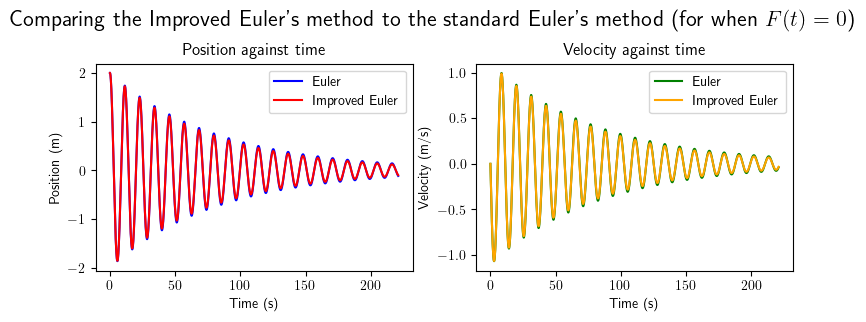

In [80]:
# Plot the solutions found from Euler's method with the Improved Euler solutions.

plt.rcParams["figure.figsize"] = (9,3)
fig,(ax1,ax2) = plt.subplots(1,2)
fig.suptitle(r"Comparing the Improved Euler's method to the standard Euler's method (for when $F(t) = 0$)", fontsize=16)
fig.subplots_adjust(top=0.8)  # Adjust space for the title.

# Position plot.
ax1.plot(t, x_euler, "b", label="Euler")
ax1.plot(t, x_euler_imp, "r", label="Improved Euler")
ax1.set(xlabel="Time (s)")
ax1.set(ylabel="Position (m)")
ax1.set_title("Position against time", fontsize=12)
ax1.legend()

# Velocity plot.
ax2.plot(t, v_euler, "g", label="Euler")
ax2.plot(t, v_euler_imp, "orange", label="Improved Euler")
ax2.set(xlabel="Time (s)")
ax2.set(ylabel="Velocity (m/s)")
ax2.set_title("Velocity against time", fontsize=12)
ax2.legend()

### 6.4 Verlet's Method - zero external force

Verlet's Method starts by looking at a centred derivitive. The derivation is a bit long. Only final equation will be implemented.

$x'(t) = \lim_{h \to 0} \frac{x(t+h) - x(t-h)}{2h}$

From which we can determine:

$v_i = \frac{x_{i+1} - x_{i-1}}{2h} + O(h^2)$

$a_i = \frac{x_{i+1} + x_{i-1} - 2x_i}{h^2} + O(h^2)$

Rearranging to find:

$x_{i+1} = 2x_i - x_{i-1} + h^2 a_i + O(h^4)$ Note the error is of a fourth order, more accurate.

$a_i = -\frac{k}{m} x_i - \frac{b}{m} v_i$

$v_i = \frac{x_{i+1} - x_{i-1}}{2h}$

Rearranging so that it is only in terms of $x$.

$x_{i+1} = A x_i + B x_{i-1}$,

where $A = 2 \frac{(2m - k h^2)}{D}, \quad B = \frac{(b h - 2m)}{D}, \quad D = 2m + b h$

Here we can see Verlet's method is not self starting. We must know the previous term $i-1$. Therefore an alternative method must be used for the first step.

In [81]:
def verlets_method(h, T, x_0, v_0, b=b_1):
    """
    h is the step size in seconds.
    T is the time we are integrating until, in seconds.
    x_0 is the initial condition for position.
    v_0 is the initial condition for velocity.
    b is the damping constant. It is b_1 unless stated otherwise.

    This function uses the equations in the above markdown to carry out Verlet's numerical method.

    For the first step it must use another method as discussed in the above markdown. Improved euler's is used here for more accuracy.

    It returns the arrays of position, velocity & time.
    """
    
    no_steps = int(T/h) # Determine how many whole number steps are within T. Each step is one i.

    t = np.arange(0, (no_steps * h), h) # Define time intervals for each step. Useful for when we plot.
    
    x = np.zeros(no_steps) # Empty array for position.
    v = np.zeros(no_steps) # Empty array for velocity.

    # Use the initial conditions from the function arguments.
    x[0] = x_0
    v[0] = v_0
    
    D = 2 * m + b * h

    A =  2 * (2 * m - k * h**2) / D

    B = (b * h - 2 * m) / D

    # Use improved euler's method to find (i) from (i - 1)

    # Using x_0 / x[0] as (i - 1) and x_1 / x[1] as (i) for example.

    a_0 = -(k / m) * x[0] - (b / m) * v[0] # Acceleration at step (i - 1)

    x[1] = x_1 = x[0] + h * v[0] + h**2 * a_0 / 2
    v[1] = v_1 = v[0] + h * a_0

    

    for i in range(1, no_steps - 1): # The first argument in range starts the for loop at index 1 (i). If we started from index 0 we would not be able to access (i - 1).

        x[i+1] = (A * x[i]) + (B * x[i-1])

        v[i] = (x[i+1] - x[i-1]) / (2 * h) # Incase we are interested in velocity. Although we'll have one less term.

    return x, v, t

Below I define a Verlet's method with Standard Euler's as the initialisation step. This won't be used until section 4.1. 

In [82]:
def verlets_method_standard(h, T, x_0, v_0, b=b_1):
    """
    h is the step size in seconds.
    T is the time we are integrating until, in seconds.
    x_0 is the initial condition for position.
    v_0 is the initial condition for velocity.
    b is the damping constant. It is b_1 unless stated otherwise.

    This function uses the equations in the above markdown to carry out Verlet's numerical method.

    For the first step it must use another method as discussed in the above markdown. Standard euler's is used here.

    It returns the arrays of position, velocity & time.
    """
    
    no_steps = int(T/h) # Determine how many whole number steps are within T. Each step is one i.

    t = np.arange(0, (no_steps * h), h) # Define time intervals for each step. Useful for when we plot.
    
    x = np.zeros(no_steps) # Empty array for position.
    v = np.zeros(no_steps) # Empty array for velocity.

    # Use the initial conditions from the function arguments.
    x[0] = x_0
    v[0] = v_0
    
    D = 2 * m + b * h

    A =  2 * (2 * m - k * h**2) / D

    B = (b * h - 2 * m) / D

    # Use euler's method to find (i) from (i - 1)

    # Using x_0 / x[0] as (i - 1) and x_1 / x[1] as (i) for example.

    a_0 = -(k / m) * x[0] - (b / m) * v[0] # Acceleration at step (i - 1)

    x[1] = x_1 = x[0] + h * v[0] # + h**2 * a_0 / 2 (Removing the improved euler part)
    v[1] = v_1 = v[0] + h * a_0

    

    for i in range(1, no_steps - 1): # The first argument in range starts the for loop at index 1 (i). If we started from index 0 we would not be able to access (i - 1).

        x[i+1] = (A * x[i]) + (B * x[i-1])

        v[i] = (x[i+1] - x[i-1]) / (2 * h) # Incase we are interested in velocity. Although we'll have one less term.

    return x, v, t

Let us plot position and compare to analytical solutions. Also will plot velocity and see what happens.

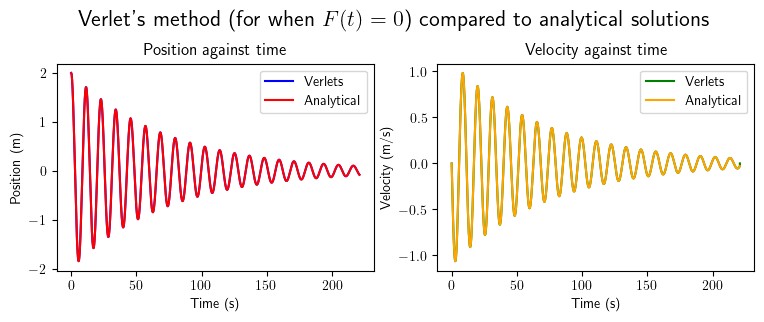

In [83]:
x_verlet, v_verlet, t_verlet = verlets_method(0.01, 221, 2, 0)

#print(len(x_verlet)) # To check whether they have a difference in number of terms by one.
#print(len(v_verlet)) # To my suprise they don't. Why?

# Plot the solutions found from the Verlet's method with the analytical solutions.

plt.rcParams["figure.figsize"] = (9,3)
fig,(ax1,ax2) = plt.subplots(1,2)
fig.suptitle(r"Verlet's method (for when $F(t) = 0$) compared to analytical solutions", fontsize=16)
fig.subplots_adjust(top=0.8)  # Adjust space for the title.

# Position plot.
ax1.plot(t, x_verlet, "b", label="Verlets")
ax1.plot(t, x_an, "r", label="Analytical")
ax1.set(xlabel="Time (s)")
ax1.set(ylabel="Position (m)")
ax1.set_title("Position against time", fontsize=12)
ax1.legend()

# Velocity plot.
ax2.plot(t, v_verlet, "g", label="Verlets")
ax2.plot(t, v_an, "orange", label="Analytical")
ax2.set(xlabel="Time (s)")
ax2.set(ylabel="Velocity (m/s)")
ax2.set_title("Velocity against time", fontsize=12)
ax2.legend()

Looks as if they are right on top of eachother, however let us check. Interestingly the Verlet's velocity seems to continue for longer than the analytical solution.

Unexpectedly velocity has the same number of terms as position. Using the equations we did, you would think that velocity has one less. Investigate?

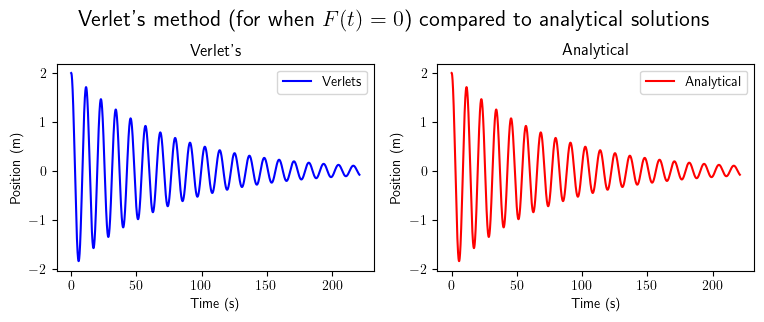

In [84]:
# Plot the position solutions found from the Verlet's method with the analytical solutions.

plt.rcParams["figure.figsize"] = (9,3)
fig,(ax1,ax2) = plt.subplots(1,2)
fig.suptitle(r"Verlet's method (for when $F(t) = 0$) compared to analytical solutions", fontsize=16)
fig.subplots_adjust(top=0.8)  # Adjust space for the title.

# Position plot.
ax1.plot(t, x_verlet, "b", label="Verlets")
ax1.set(xlabel="Time (s)")
ax1.set(ylabel="Position (m)")
ax1.set_title("Verlet's", fontsize=12)
ax1.legend()

# Velocity plot.
ax2.plot(t, x_an, "r", label="Analytical")
ax2.set(xlabel="Time (s)")
ax2.set(ylabel="Position (m)")
ax2.set_title("Analytical", fontsize=12)
ax2.legend()

They look exactly same, unlike the Euler methods there isn't that difference in amplitude that can be seen visually. Later we will check numerically. I will now do the same for velocity. 

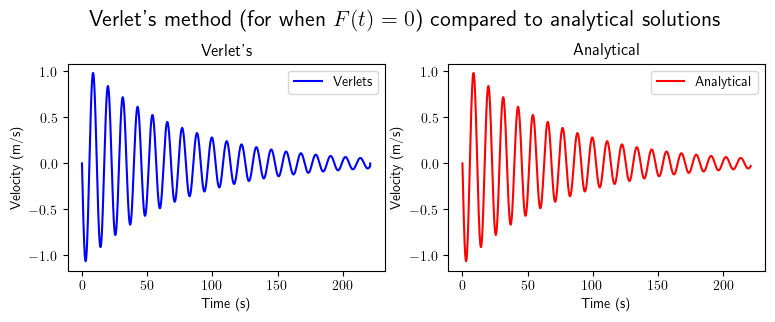

In [85]:
# Plot the velocity solutions found from the Verlet's method with the analytical solutions.

plt.rcParams["figure.figsize"] = (9,3)
fig,(ax1,ax2) = plt.subplots(1,2)
fig.suptitle(r"Verlet's method (for when $F(t) = 0$) compared to analytical solutions", fontsize=16)
fig.subplots_adjust(top=0.8)  # Adjust space for the title.

# Position plot.
ax1.plot(t, v_verlet, "b", label="Verlets")
ax1.set(xlabel="Time (s)")
ax1.set(ylabel="Velocity (m/s)")
ax1.set_title("Verlet's", fontsize=12)
ax1.legend()

# Velocity plot.
ax2.plot(t, v_an, "r", label="Analytical")
ax2.set(xlabel="Time (s)")
ax2.set(ylabel="Velocity (m/s)")
ax2.set_title("Analytical", fontsize=12)
ax2.legend()

Same as position, highly similar without the difference in amplitude. Here we can see the Verlet's velocity does continue for a bit more time or reaches a higher amplitude at the end.

In [86]:
# Trying to investigate the slight visual difference at the end. Printing each last term.
# We see that they both last the same amount of time but have different amplitudes at the end.
print(v_verlet[-1])
print(v_an[-1])

# Let us see the second to last terms.
print(v_verlet[-2])
print(v_an[-2])

# For the verlet's method is this a usual jump? I would assume no. Let us see.
average_diff_v_verlet = np.mean(np.abs(np.diff(v_verlet)))
print("Average difference between each index in v:", average_diff_v_verlet)

0.0
-0.02820093385810201
-0.02844824244619404
-0.028455393877177087
Average difference between each index in v: 0.0012207434549784217


We can see that both the second to last terms are very close and that the jump from -0.0282 to 0 is not normal. This is leading me to beleive that the verlet's velocity actually does have a term less than the position, therefore also the analytical solution to velocity. 

Looking back to my code, I have realised when creating the empty array for velocity I did so for the expected length of position. It makes sense that the final index for velocity is 0 as it was never filled. 

This tells us the visual difference seen between the verlet and analytical solution is  due to my error not the Verlet method's.

Let's plot for velocity with one less term and see.

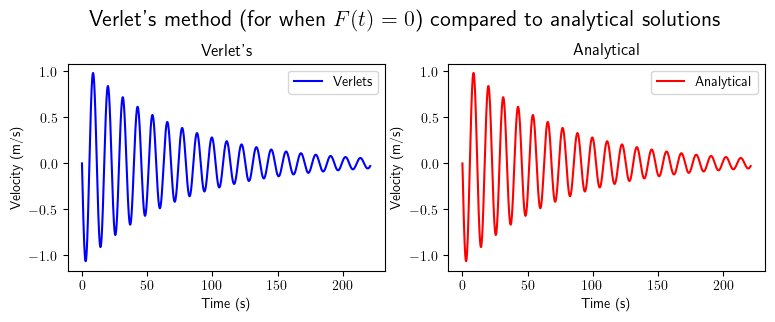

In [87]:
# Plot the velocity solutions found from the Verlet's method with the analytical solutions.

plt.rcParams["figure.figsize"] = (9,3)
fig,(ax1,ax2) = plt.subplots(1,2)
fig.suptitle(r"Verlet's method (for when $F(t) = 0$) compared to analytical solutions", fontsize=16)
fig.subplots_adjust(top=0.8)  # Adjust space for the title.

# Velocity plots.
ax1.plot(t[:-1], v_verlet[:-1], "b", label="Verlets")
ax1.set(xlabel="Time (s)")
ax1.set(ylabel="Velocity (m/s)")
ax1.set_title("Verlet's", fontsize=12)
ax1.legend()

# Velocity plot.
ax2.plot(t[:-1], v_an[:-1], "r", label="Analytical")
ax2.set(xlabel="Time (s)")
ax2.set(ylabel="Velocity (m/s)")
ax2.set_title("Analytical", fontsize=12)
ax2.legend()

With this adjustment we can see the error was not the fault of the Verlet method.

Let us see how Verlet's method holds up for different initial conditions. 

$x_0 = 1$m $v_0 = 4$m/s

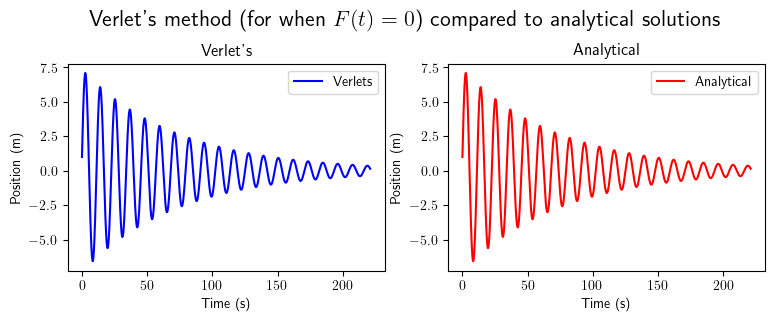

In [88]:
x_verlet1, v_verlet1, t_verlet1 = verlets_method(0.01, 221, 1, 4)

x_an_ver1, v_an_ver1, t_an_ver1 = analytical_solutions(0.01, 221, 1, 4)

# Plot the solutions found from the Verlet's method with the analytical solutions.

plt.rcParams["figure.figsize"] = (9,3)
fig,(ax1,ax2) = plt.subplots(1,2)
fig.suptitle(r"Verlet's method (for when $F(t) = 0$) compared to analytical solutions", fontsize=16)
fig.subplots_adjust(top=0.8)  # Adjust space for the title.

# Position plots
ax1.plot(t, x_verlet1, "b", label="Verlets")
ax1.set(xlabel="Time (s)")
ax1.set(ylabel="Position (m)")
ax1.set_title("Verlet's", fontsize=12)
ax1.legend()


ax2.plot(t, x_an_ver1, "r", label="Analytical")
ax2.set(xlabel="Time (s)")
ax2.set(ylabel="Position (m)")
ax2.set_title("Analytical", fontsize=12)
ax2.legend()

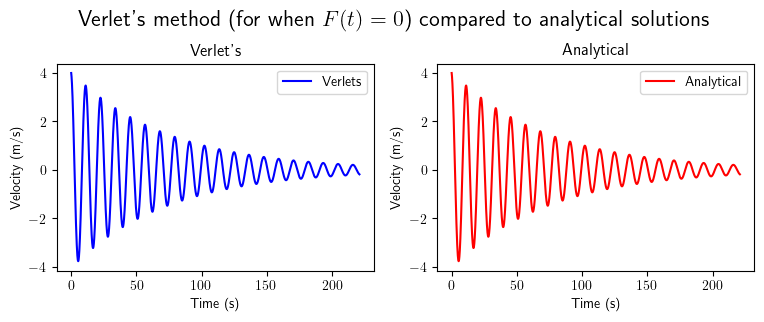

In [89]:
# Plot the solutions found from the Verlet's method with the analytical solutions.

plt.rcParams["figure.figsize"] = (9,3)
fig,(ax1,ax2) = plt.subplots(1,2)
fig.suptitle(r"Verlet's method (for when $F(t) = 0$) compared to analytical solutions", fontsize=16)
fig.subplots_adjust(top=0.8)  # Adjust space for the title.

# Velocity plots
ax1.plot(t[:-1], v_verlet1[:-1], "b", label="Verlets")
ax1.set(xlabel="Time (s)")
ax1.set(ylabel="Velocity (m/s)")
ax1.set_title("Verlet's", fontsize=12)
ax1.legend()


ax2.plot(t[:-1], v_an_ver1[:-1], "r", label="Analytical")
ax2.set(xlabel="Time (s)")
ax2.set(ylabel="Velocity (m/s)")
ax2.set_title("Analytical", fontsize=12)
ax2.legend()

The Verlet's method matches the analytical solution here for different initial conditions.

As Verlet's method seems so close to the analytical solutions in these circumstances, we will see that the other methods (Euler's & Improved Euler's) compare to Verlet's as they do to the analytical solutions.

For an example I will compare the Verlet's method with the improved Euler's method, with the initial conditions $x_0 = 2$m $v_0 = 0$m/s

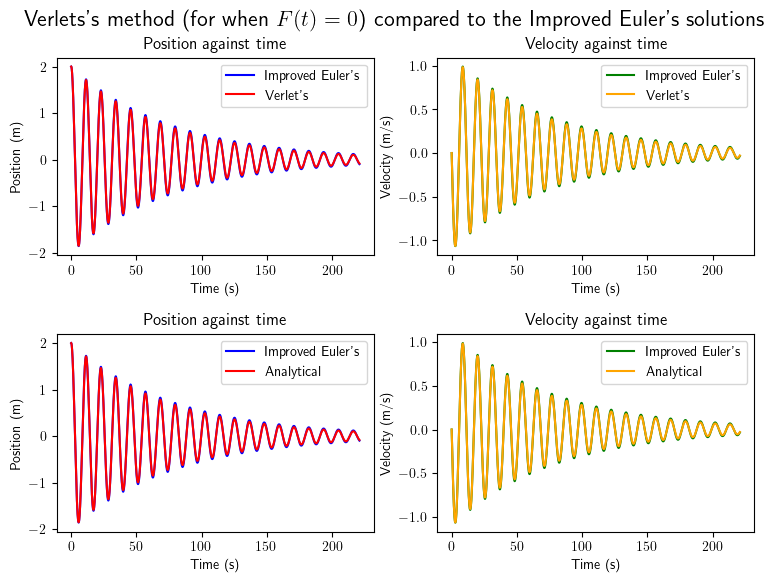

In [90]:
# Plot the solutions found from the Verlet's method with the Improved Euler solutions.

plt.rcParams["figure.figsize"] = (9,6)
fig,((ax1,ax2), (ax3,ax4)) = plt.subplots(2,2)
fig.suptitle(r"Verlets's method (for when $F(t) = 0$) compared to the Improved Euler's solutions", fontsize=16)
fig.subplots_adjust(top=0.9, hspace=0.4)  # Adjust space for the title.

# Position plot.
ax1.plot(t, x_euler_imp, "b", label="Improved Euler's")
ax1.plot(t, x_verlet, "r", label="Verlet's")
ax1.set(xlabel="Time (s)")
ax1.set(ylabel="Position (m)")
ax1.set_title("Position against time", fontsize=12)
ax1.legend()

# Velocity plot.
ax2.plot(t[:-1], v_euler_imp[:-1], "g", label="Improved Euler's")
ax2.plot(t[:-1], v_verlet[:-1], "orange", label="Verlet's")
ax2.set(xlabel="Time (s)")
ax2.set(ylabel="Velocity (m/s)")
ax2.set_title("Velocity against time", fontsize=12)
ax2.legend()

# Plot the solutions found from the Improved Euler's method with the analytical solutions.

# Position plot.
ax3.plot(t, x_euler_imp, "b", label="Improved Euler's")
ax3.plot(t, x_an, "r", label="Analytical")
ax3.set(xlabel="Time (s)")
ax3.set(ylabel="Position (m)")
ax3.set_title("Position against time", fontsize=12)
ax3.legend()

# Velocity plot.
ax4.plot(t[:-1], v_euler_imp[:-1], "g", label="Improved Euler's")
ax4.plot(t[:-1], v_an[:-1], "orange", label="Analytical")
ax4.set(xlabel="Time (s)")
ax4.set(ylabel="Velocity (m/s)")
ax4.set_title("Velocity against time", fontsize=12)
ax4.legend()

As thought the Improved Euler's method (visually) compares to Verlet's method as it does to the analytical solution.

### 6.5 Euler-Cromer Method - zero external force

The Euler-Cromer method is an adjustment on the Euler's method.

Original Euler's method:

$x_{i+1} = x_i + hv_i$

$v_{i+1} = v_i + ha_i$

where $a_i = -\frac{k}{m}x_i - \frac{b}{m}v_i$

Euler-Cromer adjustment:

$x_{i+1} = x_i +hv_{i+1}$

$v_{i+1} = v_i + ha_i$

The Euler-Cromer is a Symplectic Integrator, energy preserving. We will come to why later.

In [91]:
def euler_cromer_method(h, T, x_0, v_0, b=b_1):
    """
    h is the step size in seconds.
    T is the time we are integrating until, in seconds.
    x_0 is the initial condition for position.
    v_0 is the initial condition for velocity.
    b is the damping constant. It is b_1 unless stated otherwise.

    This function uses the equations in the above markdown to carry out the Euler-Cromer numerical method.

    It returns the arrays of position, velocity & time.
    """

    no_steps = int(T/h) # Determine how many whole number steps are within T. Each step is one i.
    
    x = np.zeros(no_steps) # Empty array for position.
    v = np.zeros(no_steps) # Empty array for velocity.

    # Use the initial conditions from the function arguments.
    x[0] = x_0
    v[0] = v_0

    for i in range(no_steps - 1):

        a = -(k / m) * x[i] - (b / m) * v[i]
        v[i+1] = v[i] + h * a # v at later step i+1
        x[i+1] = x[i] + h * v[i+1] # x at later step i+1
        

    t = np.arange(0, (no_steps * h), h) # Define time intervals for each step. Useful for when we plot.
    # Returning them each time may not be that useful as they should all be the same but I will keep it for when we adjust h & T.
    
    return x, v, t

Let us plot and compare to analytical solutions, for initial conditions $x_0 = 2$m $v_0 = 0$m/s.

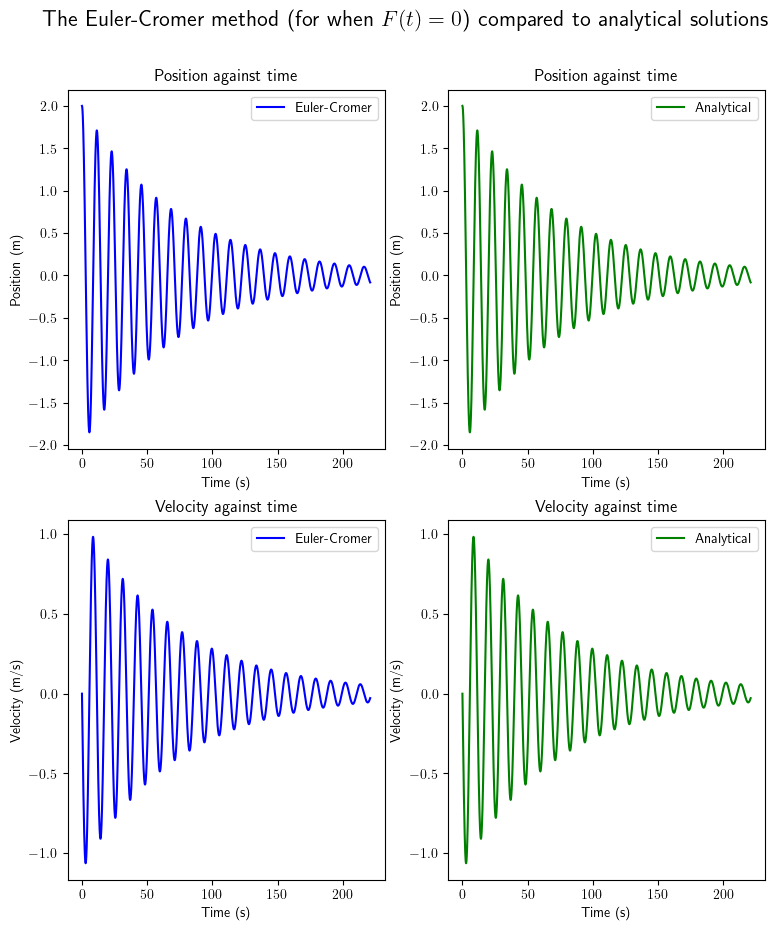

In [92]:
x_crom, v_crom, t_crom = euler_cromer_method(0.01, 221, 2, 0)

# Plot the solutions found from the Euler-Cromer method with the analytical solutions.

plt.rcParams["figure.figsize"] = (9,10)
fig,((ax1,ax2), (ax3,ax4)) = plt.subplots(2,2)
fig.suptitle(r"The Euler-Cromer method (for when $F(t) = 0$) compared to analytical solutions", fontsize=16)
fig.subplots_adjust(top=0.9)  # Adjust space for the title.

# Euler-Cromer position plot.
ax1.plot(t, x_crom, "b", label="Euler-Cromer")
ax1.set(xlabel="Time (s)")
ax1.set(ylabel="Position (m)")
ax1.set_title("Position against time", fontsize=12)
ax1.legend()

# Analytical position plot.
ax2.plot(t, x_an, "g", label="Analytical")
ax2.set(xlabel="Time (s)")
ax2.set(ylabel="Position (m)")
ax2.set_title("Position against time", fontsize=12)
ax2.legend()

# Euler-Cromer velocity plot.
ax3.plot(t, v_crom, "b", label="Euler-Cromer")
ax3.set(xlabel="Time (s)")
ax3.set(ylabel="Velocity (m/s)")
ax3.set_title("Velocity against time", fontsize=12)
ax3.legend()

# Analytical velocity plot.
ax4.plot(t, v_an, "g", label="Analytical")
ax4.set(xlabel="Time (s)")
ax4.set(ylabel="Velocity (m/s)")
ax4.set_title("Velocity against time", fontsize=12)
ax4.legend()

Looks very similar to the analytical solutions. Let us check for alternative initial conditions, $x_0 = 5$m $v_0 = -4$m/s.

In [ ]:
x_crom1, v_crom1, t_crom1 = euler_cromer_method(0.01, 221, 5, -4)

x_an_crom1, v_an_crom1, t_an_crom1 = analytical_solutions(0.01, 221, 5, -4)

# Plot the solutions found from the Euler-Cromer method with the analytical solutions.

plt.rcParams["figure.figsize"] = (9,10)
fig,((ax1,ax2), (ax3,ax4)) = plt.subplots(2,2)
fig.suptitle(r"The Euler-Cromer method (for when $F(t) = 0$) compared to analytical solutions", fontsize=16)
fig.subplots_adjust(top=0.9)  # Adjust space for the title.

# Euler-Cromer position plot.
ax1.plot(t, x_crom1, "b", label="Euler-Cromer")
ax1.set(xlabel="Time (s)")
ax1.set(ylabel="Position (m)")
ax1.set_title("Position against time", fontsize=12)
ax1.legend()

# Analytical position plot.
ax2.plot(t, x_an_crom1, "g", label="Analytical")
ax2.set(xlabel="Time (s)")
ax2.set(ylabel="Position (m)")
ax2.set_title("Position against time", fontsize=12)
ax2.legend()

# Euler-Cromer velocity plot.
ax3.plot(t, v_crom1, "b", label="Euler-Cromer")
ax3.set(xlabel="Time (s)")
ax3.set(ylabel="Velocity (m/s)")
ax3.set_title("Velocity against time", fontsize=12)
ax3.legend()

# Analytical velocity plot.
ax4.plot(t, v_an_crom1, "g", label="Analytical")
ax4.set(xlabel="Time (s)")
ax4.set(ylabel="Velocity (m/s)")
ax4.set_title("Velocity against time", fontsize=12)
ax4.legend()

Euler-Cromer matches the analytical solutions well.